In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv
/kaggle/input/competitions/comment-category-prediction-challenge/train.csv
/kaggle/input/competitions/comment-category-prediction-challenge/test.csv


In [2]:
train = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/test.csv")
submission = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv")

In [3]:
train["label"].value_counts(normalize = True)

label
0    0.576631
2    0.315354
1    0.080394
3    0.027621
Name: proportion, dtype: float64

**Importing importand models or api**

In [4]:
from datetime import datetime
from  scipy.stats import mode,randint,loguniform,uniform
from  scipy.sparse import hstack,csr_matrix
import matplotlib.pyplot as  plt
import warnings
warnings.filterwarnings("ignore")
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (MinMaxScaler,StandardScaler,OrdinalEncoder,OneHotEncoder,
                                    MaxAbsScaler,LabelEncoder,RobustScaler,FunctionTransformer,
                                    Normalizer)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import RFE,SelectKBest,f_classif
from sklearn.metrics import f1_score,make_scorer,classification_report
from sklearn.feature_extraction.text import  TfidfVectorizer,CountVectorizer
from sklearn.pipeline import Pipeline,make_pipeline
from sklearn.linear_model import LogisticRegression,SGDClassifier
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import train_test_split,RandomizedSearchCV,StratifiedKFold,GridSearchCV,HalvingGridSearchCV,HalvingRandomSearchCV
from sklearn.svm import LinearSVC
import re
from imblearn.over_sampling import SMOTE,RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier,StackingClassifier
from sklearn.metrics import f1_score,accuracy_score,precision_score,recall_score,confusion_matrix,classification_report,ConfusionMatrixDisplay
from xgboost import XGBClassifier
print("Importing Done")


Importing Done


# Appendix

## Mileston 1

In [5]:
# train.shape

In [6]:
# len(test.columns)

In [7]:
# train.info()

In [8]:
# train.isna().sum()

In [9]:
# train["label"].nunique()

In [10]:
# train["label"].value_counts(normalize =True)

In [11]:
# train["upvote"].median() #not understood question properly

In [12]:
# train["upvote"].max(),train["downvote"].max(),train["if_1"].max(),train["if_2"].max()

In [13]:
# train["if_2"].min()

In [14]:
# train.isna().sum()

## Mileston 2

In [15]:
# train["created_date"] = pd.to_datetime(train["created_date"])
# train["year"] = train["created_date"].dt.year
# train["month"] = train["created_date"].dt.month
# train["day"] = train["created_date"].dt.day
# train["hour"] = train["created_date"].dt.hour
# train["month"].value_counts(ascending = False)[:5]


In [16]:
# train["total_emoticon"] = train["emoticon_1"] + train["emoticon_2"] +train["emoticon_3"]
# train["total_emoticon"].max()


In [17]:
# comlab = train[["comment","label"]]
# com_lab_3 = comlab[comlab["label"] == 3]
# com_lab_3["comment"].str.len().median()

In [18]:
# train.head(3)

In [19]:
# train["upvote"].max(),train["upvote"].min()


**min_max_scaling = 
(x - x_min)/ (x_max - x_min)**


In [20]:
# (10-0)/(201-0)

In [21]:
# label1_comment = train[train["label"] ==1]["comment"]
# count_words = label1_comment.astype(str).apply(lambda x:len(x.split()))
# count_words.mean()

In [22]:
# train["comment"] = train["comment"].fillna("")

In [23]:
# count_trump = train["comment"].str.contains("trump",case = False,na = False).sum()
# count_trump


**case = False:because it will make case insensitive and take all trump ,like :Trump,trump,TRuMp**



**na = False: it prevents from NaN value**

In [24]:
# import re
# text = str(train["comment"][0])
# text_lower = text.lower()
# text_no_punc = re.sub(r"[^\w\s]","",text_no_punc)
# text_split = text_no_punc.split()
# text_split

In [25]:
# stop_words =  ['a', 'an', 'the', 'and', 'or', 'but', 'if', 'because', 'as', 'of', 'at', 'by', 'for', 'with', 'about', 'to', 'from', 'up', 'on', 'in', 'out', 'over', 'under', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'do', 'does', 'did', 'it', 'its', 'they', 'them', 'their', 'she', 'her', 'he', 'him', 'his', 'this', 'that', 'which', 'who', 'whom', 'i', 'me', 'my', 'we', 'our', 'you', 'your']

In [26]:
# count = 0
# for word in text_split:
#     if word not in  stop_words:
#         count+=1
# print(count)

In [27]:
# train["comment"] = train["comment"].fillna("").str.lower()
# comment = train["comment"].str.lower()
# token = comment.str.split()
# token
# all_token = []
# for listi in token:
#     for token in listi:
#         all_token.append(token)
# len(set(all_token))

In [28]:
# comments = train["comment"].fillna("")
# vectorize =  TfidfVectorizer(ngram_range = (1,2),stop_words = "english",min_df = 5)

In [29]:
# x = vectorize.fit_transform(comments)


In [30]:
# x

198000 -row(comments)


132974 -columns(Tfidf)



5560455 stored element - non zero tfidf

In [31]:
# len(vectorize.get_feature_names_out())

## Mileston 3

In [32]:
# x = train.drop(columns = ["label"])
# y = train["label"]

In [33]:
# xtrain,xtest,ytrain,ytest = train_test_split(x,y,test_size = 0.8,random_state = 42)

In [34]:
# # Q1
# a,b = xtrain.shape
# c,d = xtest.shape
# print(a,b)
# print(c,d)
# print("a+b : ",a+c)

In [35]:
# # Q2
# xtrain.head(3)

In [36]:
# xtest.head(3)

In [37]:
# xtrain["created_date"] = pd.to_datetime(xtrain["created_date"])
# xtrain["day"] = xtrain["created_date"].dt.day
# xtrain["month"] = xtrain["created_date"].dt.month
# xtrain["year"] = xtrain["created_date"].dt.year
# xtrain["hour"] = xtrain["created_date"].dt.hour
# xtrain = xtrain.drop(columns = ["created_date"])

# xtest["created_date"] = pd.to_datetime(xtest["created_date"])
# xtest["day"] = xtest["created_date"].dt.day
# xtest["month"] = xtest["created_date"].dt.month
# xtest["year"] = xtest["created_date"].dt.year
# xtest["hour"] = xtest["created_date"].dt.hour
# xtest = xtest.drop(columns = ["created_date"])


In [38]:
# xtrain["month"].value_counts()

In [39]:
# xtrain["month"].mode()

In [40]:
# xtrain.info()

In [41]:
# # Q3
# cat_col = xtrain.select_dtypes(include = "object").columns
# cat_col

In [42]:
# cat_pipe = Pipeline([
#     ("con",SimpleImputer(strategy = "constant",fill_value = "none")),
#     ("ohe",OneHotEncoder(handle_unknown = "ignore",sparse_output=False))
# ])

# ct = ColumnTransformer([
#     ("cat",cat_pipe,cat_col)
# ],remainder = "passthrough",verbose_feature_names_out = False).set_output(transform = "pandas")

In [43]:
# xtrain_ct = ct.fit_transform(xtrain)


In [44]:
# xtrain_ct.shape

In [45]:
# 39600+39624

In [46]:
# xtest_ct = ct.transform(xtest) #not working

In [47]:
# # Q4
# cv = CountVectorizer()
# xtrain_cv = cv.fit_transform(xtrain["comment"])  #xtrain_cv became sparse matrix
# xtest_cv = cv.transform(xtrain["comment"])


In [48]:
# print("Number of Document , Number of Unique words/vocabulary  : ", xtrain_cv.shape)
# print(xtrain_cv[1].sum())

**Comment has:**
* Number of Document - 39600 (rows)
* Number of Unique words/vocabulary - 67416 (columns)

In [49]:
# # Q5

# xtrain["disability"] = xtrain["disability"].map({False :0,True:1})
# print(xtrain["disability"].isna().sum())
# print(xtrain["disability"].value_counts())


In [50]:
# xtest["disability"] = xtest["disability"].map({False :0,True:1})
# print(xtest["disability"].isna().sum())
# print(xtest["disability"].value_counts())

In [51]:
# print("Sum of Disability in xtrain nad ytest : ",2227+516)

**So in xtrain there is 516 disable person and** 
**in xtest there is 2227 disable person**

In [52]:
# # Q6
# num_cols = xtrain.select_dtypes(include = "number").columns
# xtrain_num = xtrain[num_cols]
# xtrain_num


In [53]:

# xtest_num = xtest[num_cols]
# xtest_num

In [54]:
# ss = StandardScaler()
# xtrain_num_ss = ss.fit_transform(xtrain_num)
# xtest_num_ss = ss.transform(xtest_num)

In [55]:
# ss.n_features_in_   #scaling does not columns number

In [56]:
# xtrain_num_ss.shape  

In [57]:
# # # Q7

# xtrain,xtest,ytrain,ytest = train_test_split(x,y,test_size = 0.2,random_state = 42,stratify = y)

In [58]:

# impute = SimpleImputer(strategy = "most_frequent")
# xtrain = pd.DataFrame(impute.fit_transform(xtrain),columns = xtrain.columns,index = xtrain.index)
# xtest = pd.DataFrame(impute.transform(xtest),columns = xtest.columns,index = xtest.index)

In [59]:
# xtrain["created_date"] = pd.to_datetime(xtrain["created_date"])
# xtrain["day"] = xtrain["created_date"].dt.day
# xtrain["month"] = xtrain["created_date"].dt.month
# xtrain["year"] = xtrain["created_date"].dt.year
# xtrain["hour"] = xtrain["created_date"].dt.hour
# xtrain = xtrain.drop(columns = ["created_date"])

# xtest["created_date"] = pd.to_datetime(xtest["created_date"])
# xtest["day"] = xtest["created_date"].dt.day
# xtest["month"] = xtest["created_date"].dt.month
# xtest["year"] = xtest["created_date"].dt.year
# xtest["hour"] = xtest["created_date"].dt.hour
# xtest = xtest.drop(columns = ["created_date"])

In [60]:
# col_nums = xtrain.select_dtypes(include = "number").columns
# xtrain[col_nums] = xtrain[col_nums].abs()
# xtest[col_nums] = xtest[col_nums].abs()

In [61]:
# tfidf =  TfidfVectorizer(stop_words = "english")
# xtrain_tfidf = tfidf.fit_transform(xtrain["comment"])
# xtest_tfidf = tfidf.transform(xtest["comment"])

In [62]:
# xtrain.drop("comment",inplace = True,axis = 1)
# xtest.drop("comment",inplace = True,axis = 1)
# ohe = OneHotEncoder(handle_unknown = "ignore")
# cat_cols = xtrain.select_dtypes(include = "object").columns

# xtrain_cat = ohe.fit_transform(xtrain[cat_cols])
# xtest_cat = ohe.transform(xtest[cat_cols])

In [63]:
# xtrain_fit

In [64]:
# xtrain

In [65]:
# xtrain = xtrain.drop(columns = cat_cols,axis = 1)
# xtest = xtest.drop(columns = cat_cols,axis = 1)


In [66]:
# xtrain.values

In [67]:
# xtrain_tfidf

In [68]:
# xtrain_cat

In [69]:
from scipy.sparse import hstack

In [70]:
# print(xtrain.dtypes)

xtrain = xtrain.astype(float)

In [71]:
# xtrain_f = hstack([xtrain_tfidf,xtrain.values,xtrain_cat])
# xtest_f = hstack([xtest_tfidf,xtest.values,xtest_cat])

# from sklearn.naive_bayes import MultinomialNB
# model = MultinomialNB()
# xtrain_f_fit = model.fit(xtrain_f,ytrain)



In [72]:
# model_predict = model.predict(xtrain_f)
# f1_score_train = f1_score(ytrain,model_predict,average = "macro")
# f1_score_train

In [73]:
# model_predict = model.predict(xtest_f)
# f1_score_train = f1_score(ytest,model_predict,average = "macro")
# f1_score_train

In [74]:
# Q8

In [75]:
# xtrain,xtest,ytrain,ytest = train_test_split(x,y,test_size = 0.2,random_state = 42,stratify = y)

# impute = SimpleImputer(strategy = "most_frequent")
# xtrain = pd.DataFrame(impute.fit_transform(xtrain),columns = xtrain.columns,index = xtrain.index)
# xtest = pd.DataFrame(impute.transform(xtest),columns = xtest.columns,index = xtest.index)


In [76]:
# xtrain["created_date"] = pd.to_datetime(xtrain["created_date"])
# xtest["created_date"] = pd.to_datetime(xtest["created_date"])

In [77]:
# xtrain["is_weekend"] = (xtrain["created_date"].dt.day_name().isin(["Saturday","Sunday"])).astype(int)
# xtest["is_weekend"] = (xtest["created_date"].dt.day_name().isin(["Saturday","Sunday"])).astype(int)

In [78]:

# xtrain["day"] = xtrain["created_date"].dt.day
# xtrain["month"] = xtrain["created_date"].dt.month
# xtrain["year"] = xtrain["created_date"].dt.year
# xtrain["hour"] = xtrain["created_date"].dt.hour
# xtrain = xtrain.drop(columns = ["created_date"])


# xtest["day"] = xtest["created_date"].dt.day
# xtest["month"] = xtest["created_date"].dt.month
# xtest["year"] = xtest["created_date"].dt.year
# xtest["hour"] = xtest["created_date"].dt.hour
# xtest = xtest.drop(columns = ["created_date"])

In [79]:
# tfidf =  TfidfVectorizer(stop_words = "english")
# xtrain_tfidf = tfidf.fit_transform(xtrain["comment"])
# xtest_tfidf = tfidf.transform(xtest["comment"])

In [80]:
# cat_cols = xtrain.select_dtypes(include = "number").columns.tolist()
# # col_nums.append("is_weekend")

In [81]:
# cat_cols

In [82]:
# xtrain[col_nums] = xtrain[col_nums].abs()
# xtest[col_nums] = xtest[col_nums].abs()

In [83]:
# xtrain.drop("comment",inplace = True,axis = 1)
# xtest.drop("comment",inplace = True,axis = 1)


In [84]:
# ohe = OneHotEncoder(handle_unknown = "ignore")
# cat_cols = xtrain.select_dtypes(include = "object").columns

# xtrain_cat = ohe.fit_transform(xtrain[cat_cols])
# xtest_cat = ohe.transform(xtest[cat_cols])

In [85]:
# xtrain.info()

In [86]:
# xtrain = xtrain.drop(columns = cat_cols,axis = 1)
# xtest = xtest.drop(columns = cat_cols,axis = 1)

In [87]:
# xtrain_f = hstack([xtrain_tfidf,xtrain.values,xtrain_cat])
# xtest_f = hstack([xtest_tfidf,xtest.values,xtest_cat])

# from sklearn.naive_bayes import MultinomialNB
# model = MultinomialNB()
# xtrain_f_fit = model.fit(xtrain_f,ytrain)



In [88]:
# model_predict = model.predict(xtrain_f)
# f1_score_train = f1_score(ytrain,model_predict,average = "macro")
# f1_score_train

In [89]:
# model_predict = model.predict(xtest_f)
# f1_score_train = f1_score(ytest,model_predict,average = "macro")
# f1_score_train

In [90]:
# model_predict.shape

In [91]:
# model_predict = model.predict(xtest_f)
# f1_score_test = f1_score(ytest,model_predict,average = "macro")
# f1_score_test

# Dummy Sumission

In [92]:
# from sklearn.dummy import DummyClassifier

In [93]:
# dummy_model = DummyClassifier(strategy = "most_frequent")
# dummy_model.fit(xtrain,ytrain)
# dummy_pred = dummy_model.predict(test)
# dummy_pred

# Viva 1

# Data set  loading

In [94]:

train = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/test.csv")
submission = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv")

In [95]:
print("Shape of train data : ", train.shape)
print("Shape of test data : ", test.shape)

Shape of train data :  (198000, 15)
Shape of test data :  (102000, 14)


In "test" data one feature is missing that is our target column name **label**

# EDA (Explanatory Data Analysis)

## Visualisation key statistic and relationship in data

In [96]:
train.head()

,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment,label
0,2024-01-18 08:43:57.397508+00:00,73,0,0,0,0,1,0,10,NaN,NaN,NaN,False,She might be a bright spot for a party keou on...,2
1,2024-03-24 21:43:11.490017+00:00,39,0,0,0,6,0,0,4,NaN,NaN,NaN,False,"Under Alaska law, a non-tribal member is not b...",0
2,2024-04-24 20:32:17.014931+00:00,31,0,1,1,0,0,0,10,NaN,NaN,NaN,False,in the future please spare me your strawman dr...,2
3,2023-05-28 22:00:14.214527+00:00,39,0,0,0,5,0,0,10,NaN,NaN,NaN,False,"PS: That should have been ""rot"" instead of ""co...",2
4,2023-09-09 23:12:05.689498+00:00,39,0,0,0,0,0,0,10,NaN,NaN,NaN,False,"Today, the confederate flag...tomorrow, the na...",2


In [97]:
test.head()

,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment
0,2024-02-08 13:13:27.998156+00:00,72,2,0,0,4,1,0,10,NaN,NaN,NaN,False,Canada is being run by someone with the mental...
1,2024-03-01 23:33:25.547123+00:00,123,0,0,0,0,0,0,10,NaN,NaN,NaN,False,And your comment is left-wing drivel
2,2024-02-09 21:52:48.426303+00:00,120,0,0,0,3,0,0,4,NaN,NaN,NaN,False,http://talkingpointsmemo..com/dc/special-couns...
3,2024-02-17 03:43:02.980294+00:00,123,0,0,0,0,0,0,4,NaN,NaN,NaN,False,"Trump jl Blames: The Secret Service, James Com..."
4,2024-04-24 02:27:57.145155+00:00,123,0,0,0,0,0,0,11,NaN,NaN,NaN,False,It was hard enough to get the stench out of th...


In [98]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198000 entries, 0 to 197999
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   created_date  198000 non-null  object
 1   post_id       198000 non-null  int64 
 2   emoticon_1    198000 non-null  int64 
 3   emoticon_2    198000 non-null  int64 
 4   emoticon_3    198000 non-null  int64 
 5   upvote        198000 non-null  int64 
 6   downvote      198000 non-null  int64 
 7   if_1          198000 non-null  int64 
 8   if_2          198000 non-null  int64 
 9   race          52577 non-null   object
 10  religion      52577 non-null   object
 11  gender        52577 non-null   object
 12  disability    198000 non-null  bool  
 13  comment       197999 non-null  object
 14  label         198000 non-null  int64 
dtypes: bool(1), int64(9), object(5)
memory usage: 21.3+ MB


**In my train data** 
* Number columns are 9
* Category columns are 5
* Boolean column are 1


In [99]:
train.select_dtypes(include = "number")[:5]

,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,label
0,73,0,0,0,0,1,0,10,2
1,39,0,0,0,6,0,0,4,0
2,31,0,1,1,0,0,0,10,2
3,39,0,0,0,5,0,0,10,2
4,39,0,0,0,0,0,0,10,2


In [100]:
train.select_dtypes(include = "object")[:5]

,created_date,race,religion,gender,comment
0,2024-01-18 08:43:57.397508+00:00,NaN,NaN,NaN,She might be a bright spot for a party keou on...
1,2024-03-24 21:43:11.490017+00:00,NaN,NaN,NaN,"Under Alaska law, a non-tribal member is not b..."
2,2024-04-24 20:32:17.014931+00:00,NaN,NaN,NaN,in the future please spare me your strawman dr...
3,2023-05-28 22:00:14.214527+00:00,NaN,NaN,NaN,"PS: That should have been ""rot"" instead of ""co..."
4,2023-09-09 23:12:05.689498+00:00,NaN,NaN,NaN,"Today, the confederate flag...tomorrow, the na..."


In [101]:
print("Number columns are : ",train.select_dtypes(include = "number").columns)

Number columns are :  Index(['post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote',
       'downvote', 'if_1', 'if_2', 'label'],
      dtype='object')


**Number columns are** : 'post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote',
       'downvote', 'if_1', 'if_2', 'label'

In [102]:
print("Category columns are : ",train.select_dtypes(include = "object").columns)

Category columns are :  Index(['created_date', 'race', 'religion', 'gender', 'comment'], dtype='object')


**Category columns are** : 'created_date', 'race', 'religion', 'gender', 'comment'

In [103]:
print("Boolean columns are : ",train.select_dtypes(include = "boolean").columns)

Boolean columns are :  Index(['disability'], dtype='object')


**Boolean columns are** : 'disability'

In [104]:
train.isna().sum()

created_date         0
post_id              0
emoticon_1           0
emoticon_2           0
emoticon_3           0
upvote               0
downvote             0
if_1                 0
if_2                 0
race            145423
religion        145423
gender          145423
disability           0
comment              1
label                0
dtype: int64

**Our four column only hold null values:**
* Race contains 145423 null values
* Religion contains 145423 null values
* Gender contains 145423 null values
* Disability contains 1 null values

**We can see that race,disability and gender conatains same amount of null values**

In [105]:
train[train["comment"].isna()]

,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment,label
99535,2024-04-18 06:40:48.161601+00:00,31,0,0,0,1,0,4,4,none,none,none,False,NaN,0


**So in index 99535 our comment has null value**

In [106]:
train[train["comment"].isna()].index

Index([99535], dtype='int64')

dtype='int64' indicates index values are stored in 64-bit integer in pandas

In [107]:
print("Null in percentage")
((train.isna().sum()/train.shape[0])*100).sort_values(ascending = False)

Null in percentage


gender          73.445960
race            73.445960
religion        73.445960
comment          0.000505
created_date     0.000000
post_id          0.000000
emoticon_1       0.000000
downvote         0.000000
upvote           0.000000
emoticon_3       0.000000
emoticon_2       0.000000
if_1             0.000000
if_2             0.000000
disability       0.000000
label            0.000000
dtype: float64

**Here I founded null values of each column of our train data in percentage**

In [108]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
post_id,198000.0,68.447429,27.948390,20.0,39.0,72.0,72.0,129.0
emoticon_1,198000.0,0.279768,1.023234,0.0,0.0,0.0,0.0,47.0
emoticon_2,198000.0,0.048338,0.258477,0.0,0.0,0.0,0.0,11.0
emoticon_3,198000.0,0.121071,0.481013,0.0,0.0,0.0,0.0,17.0
upvote,198000.0,2.607975,5.054763,0.0,0.0,1.0,3.0,201.0
downvote,198000.0,0.666394,2.044335,0.0,0.0,0.0,1.0,107.0
if_1,198000.0,1.906152,25.635752,0.0,0.0,0.0,4.0,1860.0
if_2,198000.0,7.956212,14.839464,3.0,4.0,6.0,10.0,1833.0
label,198000.0,0.793965,0.979808,0.0,0.0,0.0,2.0,3.0


In [109]:
train["label"].value_counts()

label
0    114173
2     62440
1     15918
3      5469
Name: count, dtype: int64

In [110]:
train["gender"].value_counts()

gender
none           36161
female          8037
male            7549
transgender      622
other            208
Name: count, dtype: int64

In [111]:
train["gender"].isna().sum()

np.int64(145423)

**In Gender column:**
* none are 36161
* female  are      8037
* male   are     7549
* transgender are    622
* other    are     208
* null     are    145423
* Sum of all this make total number of rows in our data : 36161+8037+7549+622+208+145423 = 198000   

In [112]:
36161+8037+7549+622+208+145423

198000

In [113]:
print(f"Not null value in gender :{(36161+8037+7549+622+208)/198000*100:.2f}%")
print(f"Null value in gender :{(145423)/198000*100:.2f}%")

Not null value in gender :26.55%
Null value in gender :73.45%


In [114]:
print(train["race"].value_counts());
print("Null      " ,train["race"].isna().sum())

race
none      39682
white      5486
black      3869
other      1654
asian      1263
latino      623
Name: count, dtype: int64
Null       145423


In [115]:
print(train["religion"].value_counts())
print("Null        " ,train["religion"].isna().sum())

religion
none         38249
christian     7191
muslim        4930
jewish        1244
other          547
atheist        219
buddhist       100
hindu           97
Name: count, dtype: int64
Null         145423


We can see that in my Data **religion**,**gender** and **race** has null value around 73.45%.

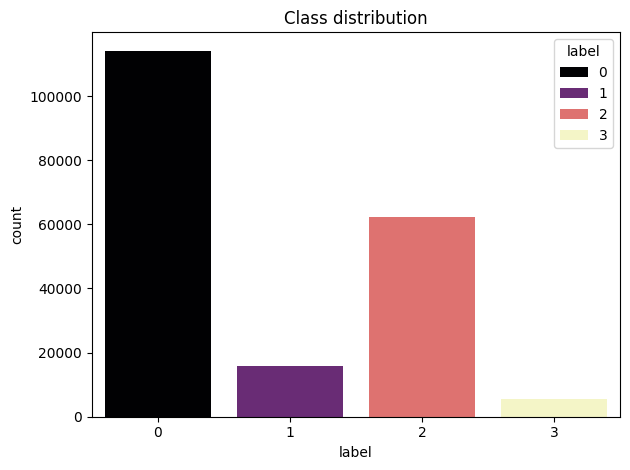

In [116]:
sns.set_theme
sns.countplot(x = "label",data = train,hue = "label",palette = "magma")
plt.title("Class distribution")
plt.tight_layout()  #for fixing space
plt.show()

**Our label is imbalance : Count 0 label is highest and second highest label is 2 and third highest is 1 and last is label 3**

**Little about color**
* color  = for single color
* hue = color based on category
* palette = style of color

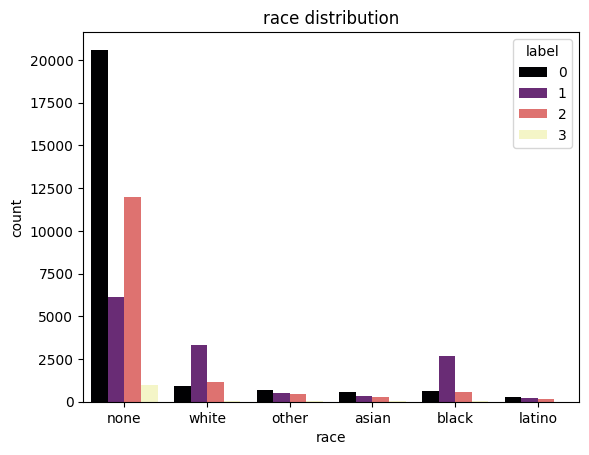

In [117]:
sns.set_theme
sns.countplot(x = "race",data = train,hue = "label",palette = "magma")
plt.title("race distribution")
plt.show()

* In this race distribution graph,our data is very much imbalance because
* "none" is highest and "none" has highest number of labels count.

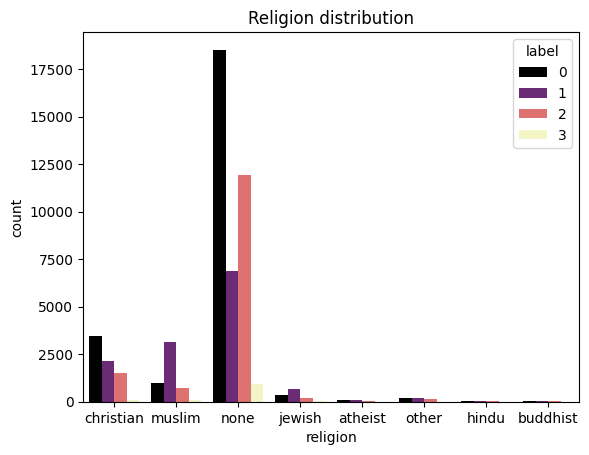

In [118]:
sns.set_theme
sns.countplot(x = "religion",data = train,hue = "label",palette = "magma")
plt.title("Religion distribution")
plt.show()

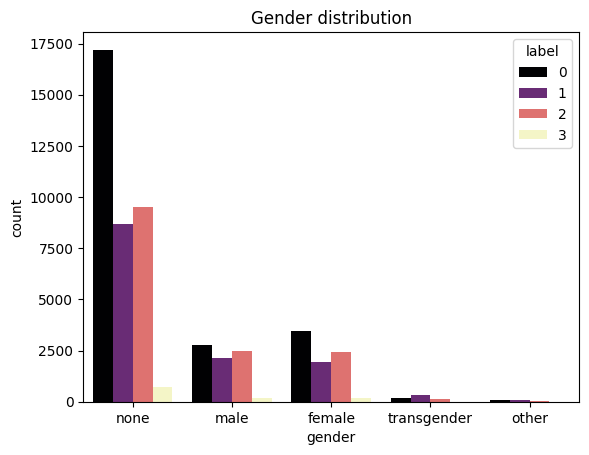

In [119]:
sns.set_theme
sns.countplot(x = "gender",data = train,hue = "label",palette = "magma")
plt.title("Gender distribution")
plt.show()

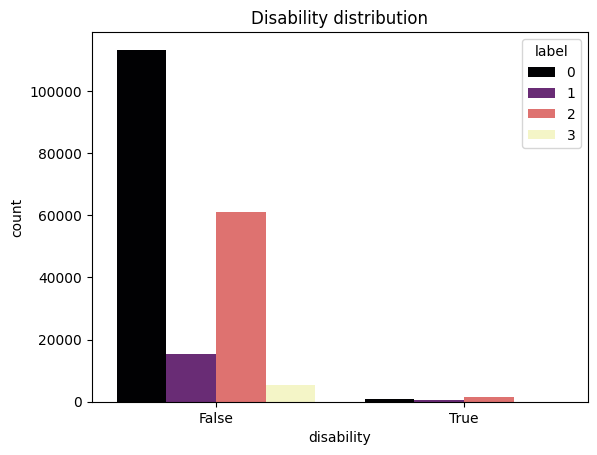

In [120]:
sns.set_theme
sns.countplot(x = "disability",data = train,hue = "label",palette = "magma")
plt.title("Disability distribution")
plt.show()

In [121]:
train["disability"].value_counts()

disability
False    195257
True       2743
Name: count, dtype: int64

In [122]:
train["disability"].value_counts(normalize = True)*100

disability
False    98.614646
True      1.385354
Name: proportion, dtype: float64

**In our train data disable people are very less which is very good but on other side our data becomes 
very much imbalance because 2743 are disable and 195257 are not disable that means 1.38 are disable and 98.61 are not disable**

In [123]:
test["disability"].value_counts()

disability
False    100644
True       1356
Name: count, dtype: int64

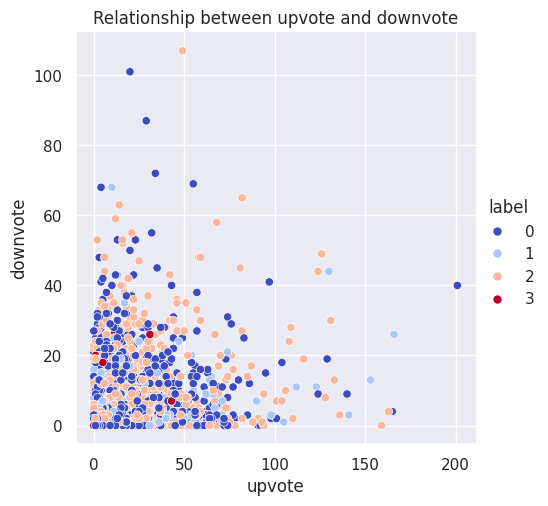

In [124]:
sns.set_theme()
sns.relplot(x = "upvote",y = "downvote",hue = "label",palette = "coolwarm",data = train)
plt.title("Relationship between upvote and downvote")
plt.show()


In [125]:
train[["upvote","downvote"]]

,upvote,downvote
0,0,1
1,6,0
2,0,0
3,5,0
4,0,0
...,...,...
197995,2,0
197996,1,0
197997,0,0
197998,5,7


In [126]:
train["upvote"].value_counts()

upvote
0      79171
1      36845
2      22332
3      15128
4      10367
       ...  
163        1
112        1
153        1
126        1
130        1
Name: count, Length: 122, dtype: int64

In [127]:
train["downvote"].value_counts()

downvote
0      147636
1       24693
2       10498
3        5430
4        3122
        ...  
65          1
63          1
87          1
107         1
49          1
Name: count, Length: 62, dtype: int64

As number increases **downvote** and **upvote** are decreases

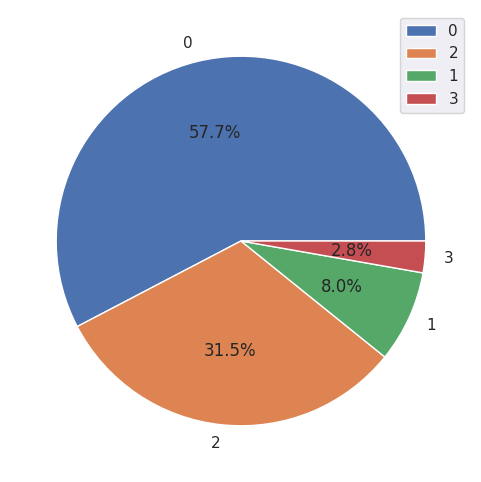

In [128]:

plt.figure(figsize = (6,6))
plt.pie(train["label"].value_counts(),autopct = "%1.1f%%",labels = train["label"].value_counts().index)
plt.legend()
plt.show()

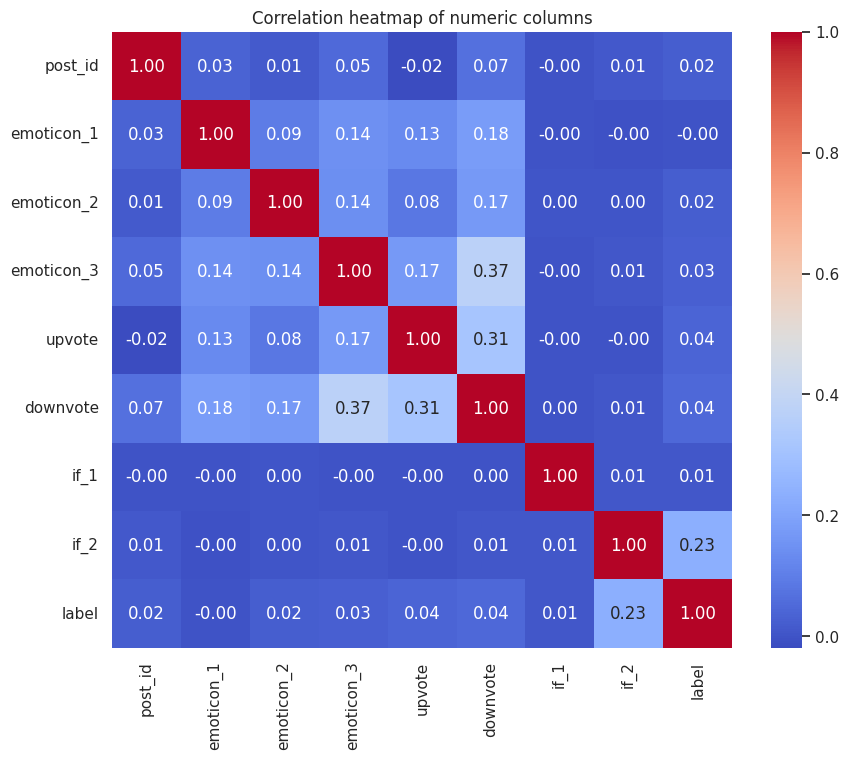

In [129]:
train_number = train.select_dtypes(include = "number")
plt.figure(figsize = (10,8))
sns.heatmap(train_number.corr(),annot = True,cmap = "coolwarm",fmt = ".2f")
plt.title("Correlation heatmap of numeric columns")
plt.show()

**Highest correlation is between emoticon_3 and downvote
and secound upvote and downvote and third is if_2 and 
label and all other are between  0-0.18**

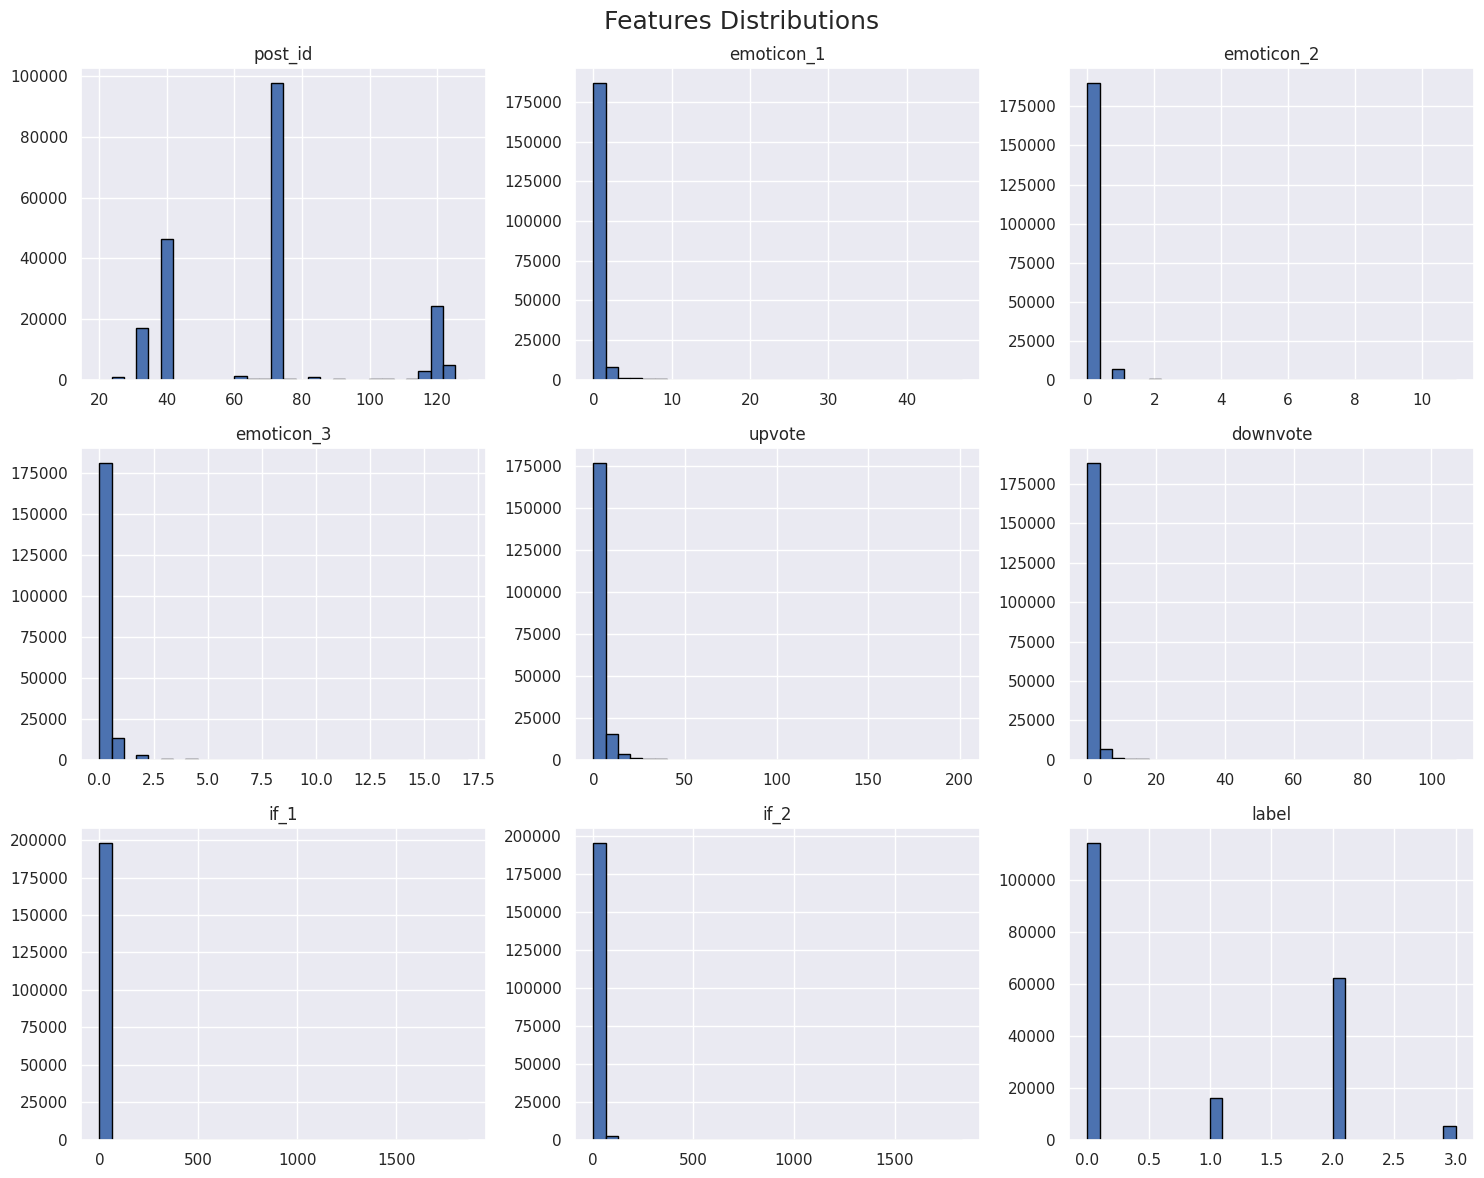

In [130]:
sns.set_theme
train.hist(figsize = (15,12),bins = 30,edgecolor = "black")
plt.suptitle("Features Distributions",fontsize = 18)
plt.tight_layout()
plt.show()

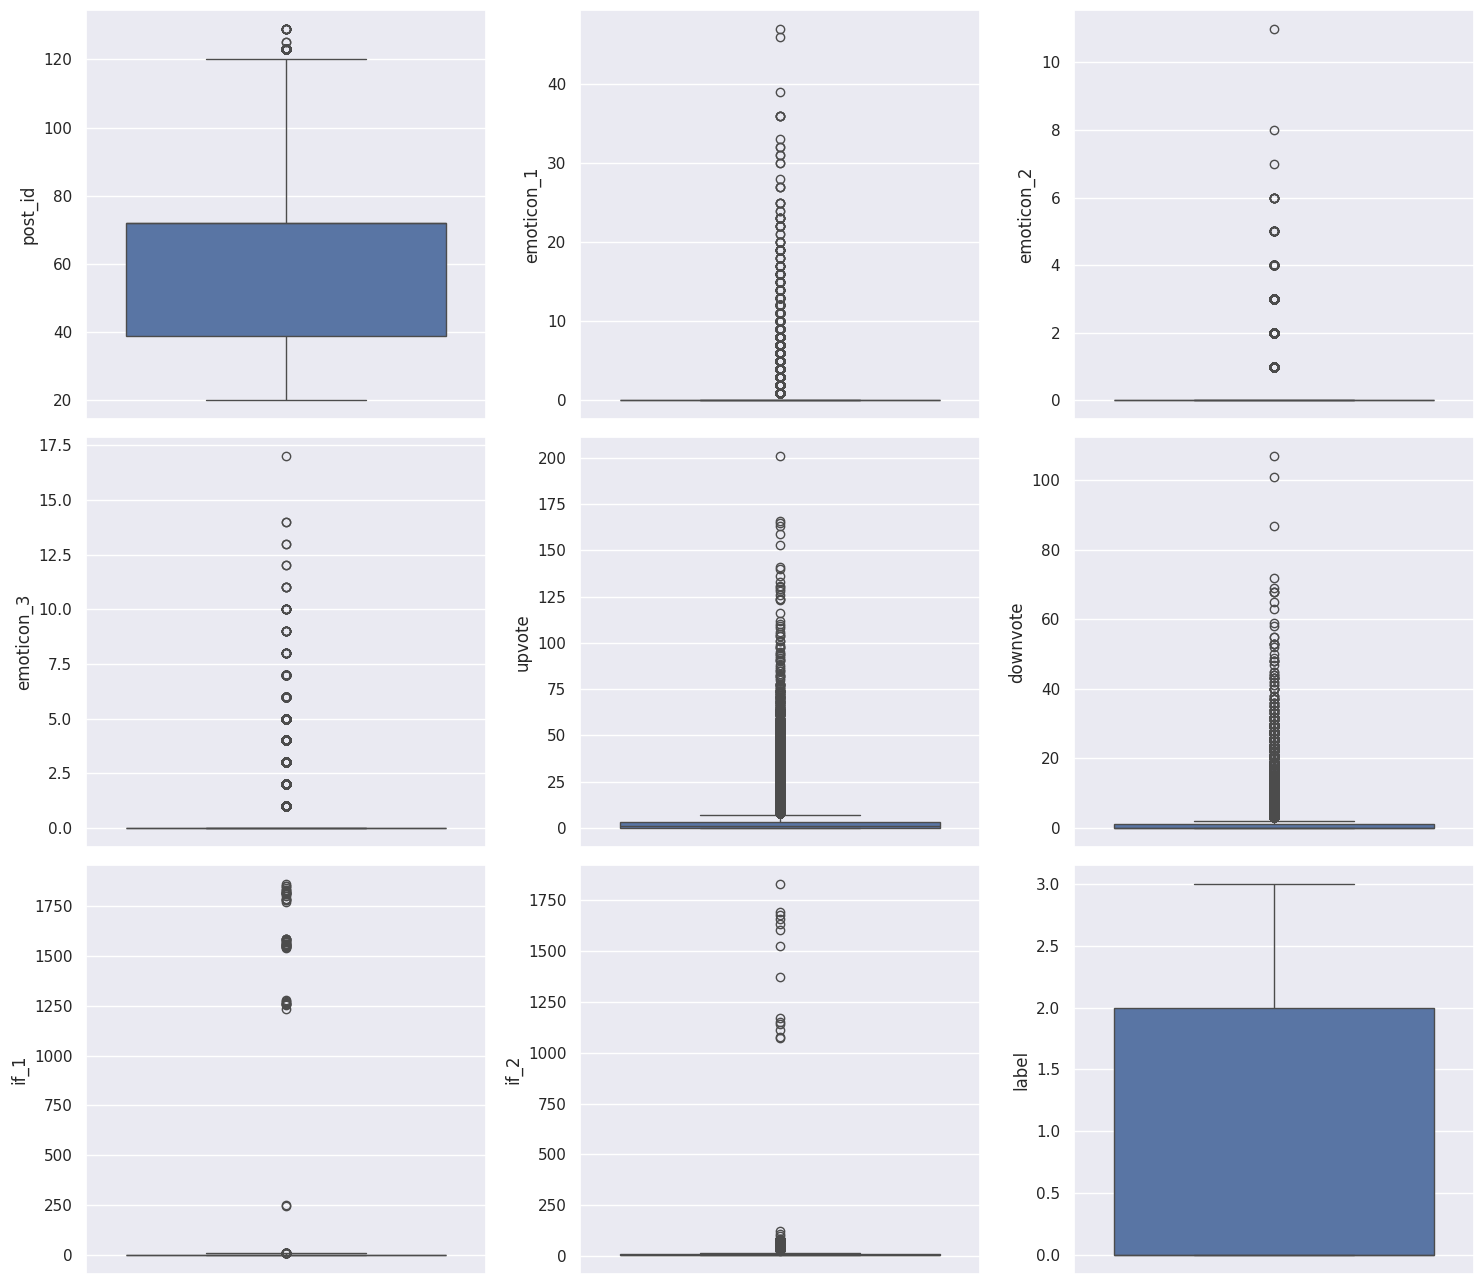

In [131]:
plt.figure(figsize = (15,13))
for i,column in enumerate(train.select_dtypes(include = "number").columns,1):
    plt.subplot(3,3,i)
    sns.boxplot(train[column])
plt.tight_layout()
plt.show()


In [132]:
train["emoticon_1"].value_counts()

emoticon_1
0     169078
1      17683
2       5799
3       2362
4       1243
5        638
6        374
7        225
8        162
9        102
10        69
11        68
12        40
13        27
15        20
16        20
14        19
19        13
17         9
23         7
22         6
20         5
18         5
36         4
25         4
27         3
24         2
21         2
31         2
30         2
32         2
28         1
46         1
33         1
47         1
39         1
Name: count, dtype: int64

In [133]:
train["emoticon_2"].value_counts()

emoticon_2
0     189891
1       7031
2        822
3        177
4         48
5         21
6          7
8          1
11         1
7          1
Name: count, dtype: int64

In [134]:
train["emoticon_3"].value_counts()

emoticon_3
0     180835
1      13017
2       2777
3        764
4        309
5        132
6         79
7         41
8         14
10        12
9          9
11         4
14         2
13         2
12         2
17         1
Name: count, dtype: int64

In [135]:
train["if_1"].value_counts()

if_1
0       145423
4        31061
10       11849
6         6774
5         2691
7           70
9           45
11          32
12           2
1814         2
1545         2
1783         2
8            2
1551         2
249          1
1569         1
1800         1
1560         1
1263         1
1267         1
1258         1
1543         1
250          1
1815         1
1538         1
1585         1
1830         1
1277         1
1807         1
1810         1
1777         1
1848         1
1257         1
1548         1
1232         1
1583         1
1572         1
1576         1
1256         1
1566         1
1547         1
1825         1
1271         1
1838         1
1553         1
1846         1
1558         1
1557         1
1767         1
1819         1
1581         1
1254         1
1811         1
1860         1
1778         1
1827         1
1584         1
Name: count, dtype: int64

In [136]:
train["if_2"].value_counts()

if_2
4       91726
10      80693
6       14558
5        6188
70        453
        ...  
1694        1
1527        1
1071        1
110         1
1171        1
Name: count, Length: 81, dtype: int64

label
0    114173
2     62440
1     15918
3      5469
Name: count, dtype: int64


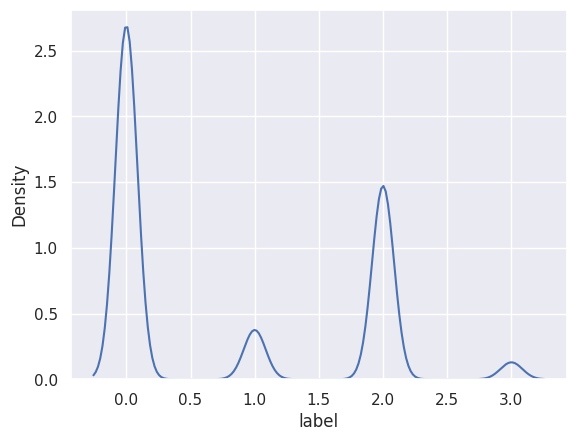

In [137]:
print(train["label"].value_counts())
sns.set_theme
sns.kdeplot(train["label"]);

## Correctly identify datatypes

In [138]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198000 entries, 0 to 197999
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   created_date  198000 non-null  object
 1   post_id       198000 non-null  int64 
 2   emoticon_1    198000 non-null  int64 
 3   emoticon_2    198000 non-null  int64 
 4   emoticon_3    198000 non-null  int64 
 5   upvote        198000 non-null  int64 
 6   downvote      198000 non-null  int64 
 7   if_1          198000 non-null  int64 
 8   if_2          198000 non-null  int64 
 9   race          52577 non-null   object
 10  religion      52577 non-null   object
 11  gender        52577 non-null   object
 12  disability    198000 non-null  bool  
 13  comment       197999 non-null  object
 14  label         198000 non-null  int64 
dtypes: bool(1), int64(9), object(5)
memory usage: 21.3+ MB


In [139]:
print("Numerical data :",train.select_dtypes(include = "number").columns)
train.select_dtypes(include = "number")[:5]

Numerical data : Index(['post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote',
       'downvote', 'if_1', 'if_2', 'label'],
      dtype='object')


,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,label
0,73,0,0,0,0,1,0,10,2
1,39,0,0,0,6,0,0,4,0
2,31,0,1,1,0,0,0,10,2
3,39,0,0,0,5,0,0,10,2
4,39,0,0,0,0,0,0,10,2


In [140]:
print("Categorical data :",train.select_dtypes(include = "object").columns)
train.select_dtypes(include = "object")[:5]

Categorical data : Index(['created_date', 'race', 'religion', 'gender', 'comment'], dtype='object')


,created_date,race,religion,gender,comment
0,2024-01-18 08:43:57.397508+00:00,NaN,NaN,NaN,She might be a bright spot for a party keou on...
1,2024-03-24 21:43:11.490017+00:00,NaN,NaN,NaN,"Under Alaska law, a non-tribal member is not b..."
2,2024-04-24 20:32:17.014931+00:00,NaN,NaN,NaN,in the future please spare me your strawman dr...
3,2023-05-28 22:00:14.214527+00:00,NaN,NaN,NaN,"PS: That should have been ""rot"" instead of ""co..."
4,2023-09-09 23:12:05.689498+00:00,NaN,NaN,NaN,"Today, the confederate flag...tomorrow, the na..."


**Numerical data** :'post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote',
       'downvote', 'if_1', 'if_2', 'label'

**Categorical data** : 'created_date', 'race', 'religion', 'gender', 'comment'

**Boolean** data type is only disability

# Missing Data and Imputation(if required)

In [141]:
print("Total Null" ,train.isna().sum().sum())
train.isna().sum()

Total Null 436270


created_date         0
post_id              0
emoticon_1           0
emoticon_2           0
emoticon_3           0
upvote               0
downvote             0
if_1                 0
if_2                 0
race            145423
religion        145423
gender          145423
disability           0
comment              1
label                0
dtype: int64

###   Data has null values with counts
* Race          :    145423
* Religion   :    145423
* Gender      :    145423
* Comment     :         1

Total Null is 436270

In [142]:
# impute = SimpleImputer(missing_values = np.nan,strategy = "most_frequent")
# train = pd.DataFrame(impute.fit_transform(train),columns = train.columns)
# train.isna().sum()

Now no missing values in my data

Converting back to DataFrame because "impute.fit_transform(train)" gives numpy array which doesnot have columns names

# Preprocessing

**Spliting the Data**

In [143]:
x = train.drop(columns = ["label"])
y = train["label"]
xtrain,xtest,ytrain,ytest = train_test_split(x,y,test_size = 0.2,stratify = y,random_state = 42)

In [144]:
print("ytrain data:\n", ytrain.value_counts(normalize = True))
print("--------------------------------")
print("ytest data:\n",ytest.value_counts(normalize = True))

ytrain data:
 label
0    0.576629
2    0.315354
1    0.080398
3    0.027620
Name: proportion, dtype: float64
--------------------------------
ytest data:
 label
0    0.576641
2    0.315354
1    0.080379
3    0.027626
Name: proportion, dtype: float64


In [145]:
xtrain.head(2)

,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment
180416,2023-09-06 14:27:15.552681+00:00,72,0,0,0,3,0,0,4,NaN,NaN,NaN,False,As a Baptist I will leave any theological diff...
135808,2024-06-01 06:33:49.922691+00:00,31,1,0,0,1,0,0,4,NaN,NaN,NaN,False,Ah ha ha ha ha ha ha ha ha ha ha ha ha ha ha h...


In [146]:
xtest.head(2)

,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment
58857,2023-08-21 21:11:58.496167+00:00,39,0,0,0,3,1,0,4,NaN,NaN,NaN,False,And what are you expecting from the Pig? Do yo...
115919,2023-07-30 19:06:20.975511+00:00,72,0,0,0,1,0,0,4,NaN,NaN,NaN,False,Your post is mostly ifction.


In [147]:
train.shape,test.shape

((198000, 15), (102000, 14))

In [148]:
print("Shape of a xtrain data : ",xtrain.shape)
print("Shape of a xtest data : ",xtest.shape)
print(" ")
print("Shape of a ytrain data : ",ytrain.shape)
print("Shape of a ytest data : ",ytest.shape)


Shape of a xtrain data :  (158400, 14)
Shape of a xtest data :  (39600, 14)
 
Shape of a ytrain data :  (158400,)
Shape of a ytest data :  (39600,)


In [149]:
xtrain["comment"] = xtrain["comment"].fillna("Unknown")
xtest["comment"] = xtest["comment"].fillna("Unknown")
test["comment"] = test["comment"].fillna("Unknown")

In [150]:
xtrain["created_date"] = pd.to_datetime(xtrain["created_date"])
xtrain["year"] = xtrain["created_date"].dt.year
xtrain["month"] = xtrain["created_date"].dt.month
xtrain["day"] = xtrain["created_date"].dt.day
xtrain["hour"] = xtrain["created_date"].dt.hour

xtest["created_date"] = pd.to_datetime(xtest["created_date"])
xtest["year"] = xtest["created_date"].dt.year
xtest["month"] = xtest["created_date"].dt.month
xtest["day"] = xtest["created_date"].dt.day
xtest["hour"] = xtest["created_date"].dt.hour

test["created_date"] = pd.to_datetime(test["created_date"])
test["year"] = test["created_date"].dt.year
test["month"] = test["created_date"].dt.month
test["day"] = test["created_date"].dt.day
test["hour"] = test["created_date"].dt.hour
# xtrain = xtrain.drop("created_date",axis = 1)
# xtest = xtest.drop("created_date",axis = 1)
# test = test.drop("created_date",axis = 1)


**Here I converted categorical "created_date" feature column to a datetime feature column and then I made new four columns with "created_date" and they are "year","month","day" and last one is "hour"** 

In [151]:
xtrain["is_weekend"] = (xtrain["created_date"].dt.day_name().isin(["Saturday","Sunday"])).astype(int)
xtest["is_weekend"] = (xtest["created_date"].dt.day_name().isin(["Saturday","Sunday"])).astype(int)
test["is_weekend"] = (test["created_date"].dt.day_name().isin(["Saturday","Sunday"])).astype(int)

**Here I created new column "is_weekend" from "created_date" and made "Saturday","Sunday" as 1 and all other day as 0 this I took help from milestone 3**

In [152]:
xtrain.head(2)

,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment,year,month,day,hour,is_weekend
180416,2023-09-06 14:27:15.552681+00:00,72,0,0,0,3,0,0,4,NaN,NaN,NaN,False,As a Baptist I will leave any theological diff...,2023,9,6,14,0
135808,2024-06-01 06:33:49.922691+00:00,31,1,0,0,1,0,0,4,NaN,NaN,NaN,False,Ah ha ha ha ha ha ha ha ha ha ha ha ha ha ha h...,2024,6,1,6,1


## Scaling numerical features and encodeing categorical features

In [153]:
xtrain.head().columns

Index(['created_date', 'post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3',
       'upvote', 'downvote', 'if_1', 'if_2', 'race', 'religion', 'gender',
       'disability', 'comment', 'year', 'month', 'day', 'hour', 'is_weekend'],
      dtype='object')

In [154]:
num_col = ['post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote','downvote', 'if_1', 'if_2',"year","month","day","hour","is_weekend"]
cat_col = ['race', 'religion', 'gender',"disability"]

preprocessing = ColumnTransformer([
    ("text",TfidfVectorizer(max_features = 1000,ngram_range = (1,1),stop_words = "english",sublinear_tf = True),"comment"),
    ("num",Pipeline([("mean",SimpleImputer(strategy = "mean")),("scale",StandardScaler())]),num_col),
    ("cate",Pipeline([("mode",SimpleImputer(strategy = "most_frequent")),("ohe",OneHotEncoder(handle_unknown = "ignore"))]),cat_col)
])


# Appropriate Pipeline if any

In [155]:
pipeline = Pipeline([
    ("pre",preprocessing),
    ("model",LogisticRegression(max_iter = 100,C=2,solver = "saga",n_jobs = -1,class_weight = "balanced"))
])

pipeline.fit(xtrain,ytrain)
predict = pipeline.predict(xtest)
f1_score(ytest,predict,average = "macro")  #0.722984176839647

0.7229271537056586

# Feature Enginearing/Extraction

Feature Enginearing/Extraction : Transforming raw data to a useful signals that helps the model to learn better

In [156]:
xtrain["disability"] = xtrain["disability"].map({False :0,True:1})
print("Null in disability column: ",xtrain["disability"].isna().sum())
print(xtrain["disability"].value_counts())

Null in disability column:  0
disability
0    156213
1      2187
Name: count, dtype: int64


In [157]:
test["disability"] = test["disability"].map({False :0,True:1})
print("Null in disability column: ",test["disability"].isna().sum())
print(test["disability"].value_counts())


Null in disability column:  0
disability
0    100644
1      1356
Name: count, dtype: int64


In [158]:
xtest["disability"] = xtest["disability"].map({False :0,True:1})
print("Null in disability column: ",xtest["disability"].isna().sum())
print(xtest["disability"].value_counts())

Null in disability column:  0
disability
0    39044
1      556
Name: count, dtype: int64


In [159]:
xtrain["race"].isna().sum()

np.int64(116455)

In [160]:
xtrain["race"].unique()

array([nan, 'none', 'white', 'asian', 'black', 'latino', 'other'],
      dtype=object)

In [161]:
xtrain["race"].value_counts()

race
none      31710
white      4334
black      3079
other      1309
asian      1012
latino      501
Name: count, dtype: int64

In [162]:
col_cat = ["race","religion","gender"]
imputer = SimpleImputer(strategy = "most_frequent")
xtrain[col_cat] = imputer.fit_transform(xtrain[col_cat])
xtest[col_cat] = imputer.transform(xtest[col_cat])
test[col_cat] = imputer.transform(test[col_cat])

In [163]:
xtrain["gender"].value_counts()

gender
none           145346
female           6372
male             6005
transgender       506
other             171
Name: count, dtype: int64

**Here I am imputing Categorical columns "race","religion","gender" with most frequend one.**

In [164]:
print("Null present in xtrain data after imputation: ",xtrain.isna().sum().sum())
print("Null present in ytest data after imputation: ",xtest.isna().sum().sum())

Null present in xtrain data after imputation:  0
Null present in ytest data after imputation:  0


In [165]:
xtrain = xtrain.drop("created_date",axis = 1)
xtest = xtest.drop("created_date",axis = 1)
test = test.drop("created_date",axis = 1)

xtrain["total_emoticon"] = xtrain["emoticon_1"] + xtrain["emoticon_2"] + xtrain["emoticon_3"]
xtrain["vote"] = xtrain["upvote"]+ xtrain["downvote"]
xtrain["if"] = xtrain["if_1"] + xtrain["if_2"]
# xtrain.drop(["if_1","if_2","upvote","downvote","emoticon_1","emoticon_2","emoticon_3"],inplace = True,axis = 1)

xtest["total_emoticon"] = xtest["emoticon_1"] + xtest["emoticon_2"] + xtest["emoticon_3"]
xtest["vote"] = xtest["upvote"]+ xtest["downvote"]
xtest["if"] = xtest["if_1"] + xtest["if_2"]
# xtest.drop(["if_1","if_2","upvote","downvote","emoticon_1","emoticon_2","emoticon_3"],inplace = True,axis = 1)

test["total_emoticon"] = test["emoticon_1"] + test["emoticon_2"] + test["emoticon_3"]
test["vote"] = test["upvote"]+ test["downvote"]
test["if"] = test["if_1"] + test["if_2"]
# test.drop(["if_1","if_2","upvote","downvote","emoticon_1","emoticon_2","emoticon_3"],inplace = True,axis = 1)

xtrain["vote_emoticon"] = xtrain["total_emoticon"]* xtrain["vote"]
xtest["vote_emoticon"] = xtest["total_emoticon"]* xtest["vote"]
test["vote_emoticon"] = test["total_emoticon"]* test["vote"]


**What I did here**
* Here I have droped "created_date" features from xtrain,xtest and test data
* I made one new feature column name "total_emoticon" by adding "emoticon_1","emoticon_2","emoticon_3" in xtrain,xtest and test data
* I made "vote" feature column by adding "upvote" and downvote"
* i made "if" feature column by adding "if_1" and "if_2"
* I made "vote_emoticon" feature column by multiplying "total_emoticon" and "vote"

* So here I added four new feature columns : "total_emoticon","vote","if",and last one is "vote_emoticon"

In [166]:
xtrain["vote_diff"] = xtrain["upvote"] - xtrain["downvote"]
xtrain["downvote_ratio"] = xtrain["downvote"]/(xtrain["downvote"] +xtrain["upvote"]+0.0001)
xtrain["upvote_ratio"] = xtrain["upvote"]/(xtrain["downvote"] +xtrain["upvote"]+0.0001)

xtest["vote_diff"] = xtest["upvote"] - xtest["downvote"]
xtest["downvote_ratio"] = xtest["downvote"]/(xtest["downvote"] +xtest["upvote"]+0.0001)
xtest["upvote_ratio"] = xtest["upvote"]/(xtest["downvote"] +xtest["upvote"]+0.0001)

test["vote_diff"] = test["upvote"] - test["downvote"]
test["downvote_ratio"] = test["downvote"]/(test["downvote"] +test["upvote"]+0.0001)
test["upvote_ratio"] = test["upvote"]/(test["downvote"] +test["upvote"]+0.0001)

In [167]:
xtrain.head()

,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,...,day,hour,is_weekend,total_emoticon,vote,if,vote_emoticon,vote_diff,downvote_ratio,upvote_ratio
180416,72,0,0,0,3,0,0,4,none,none,...,6,14,0,0,3,4,0,3,0.0,0.999967
135808,31,1,0,0,1,0,0,4,none,none,...,1,6,1,1,1,4,1,1,0.0,0.999900
130514,72,0,0,0,1,0,0,10,none,none,...,27,1,0,0,1,10,0,1,0.0,0.999900
195431,72,0,0,0,0,0,0,4,none,none,...,25,9,0,0,0,4,0,0,0.0,0.000000
67448,31,0,0,0,1,0,10,4,none,none,...,21,5,1,0,1,14,0,1,0.0,0.999900


In [168]:
xtrain["year_num"] = xtrain["year"].map({2022:0,2023:1,2024:0}).astype(int)
xtest["year_num"] = xtest["year"].map({2022:0,2023:1,2024:0}).astype(int)
test["year_num"] = test["year"].map({2022:0,2023:1,2024:0}).astype(int)

xtrain["if_emoticon"] = xtrain["if"]* xtrain["total_emoticon"]
xtest["if_emoticon"] = xtest["if"]* xtest["total_emoticon"]
test["if_emoticon"] = test["if"]* test["total_emoticon"]

xtrain["if_vote"] = xtrain["if"]* xtrain["vote"]
xtest["if_vote"] = xtest["if"]* xtest["vote"]
test["if_vote"] = test["if"]* test["vote"]

# xtrain["year_num"] = xtrain["year"].map({2022:0,2023:1,2024:2}).astype(int)

**Here I am making three new features "year_num",""if_emoticon" and "if_vote"**
* "year_num" geting by making 2022 to 0,2023 to 1 and 2024 to 0
* "if_emoticon" getting by  mutiplying "if" and "total_emoticon"
* "if_vote" getting by multiplying "if" and "vote"

In [169]:
xtrain.info()

<class 'pandas.core.frame.DataFrame'>
Index: 158400 entries, 180416 to 141917
Data columns (total 28 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   post_id         158400 non-null  int64  
 1   emoticon_1      158400 non-null  int64  
 2   emoticon_2      158400 non-null  int64  
 3   emoticon_3      158400 non-null  int64  
 4   upvote          158400 non-null  int64  
 5   downvote        158400 non-null  int64  
 6   if_1            158400 non-null  int64  
 7   if_2            158400 non-null  int64  
 8   race            158400 non-null  object 
 9   religion        158400 non-null  object 
 10  gender          158400 non-null  object 
 11  disability      158400 non-null  int64  
 12  comment         158400 non-null  object 
 13  year            158400 non-null  int32  
 14  month           158400 non-null  int32  
 15  day             158400 non-null  int32  
 16  hour            158400 non-null  int32  
 17  is_weekend

In [170]:
print(len(xtrain.head().columns))
xtrain.head().columns

28


Index(['post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote',
       'downvote', 'if_1', 'if_2', 'race', 'religion', 'gender', 'disability',
       'comment', 'year', 'month', 'day', 'hour', 'is_weekend',
       'total_emoticon', 'vote', 'if', 'vote_emoticon', 'vote_diff',
       'downvote_ratio', 'upvote_ratio', 'year_num', 'if_emoticon', 'if_vote'],
      dtype='object')

In [171]:
# selector = SelectKBest(score_func = f_classif,k=18)
# xtrain_new = xtrain.select_dtypes(include = "number")
# x_new = selector.fit_transform(xtrain_new,ytrain)
# selected_features = xtrain_new.columns[selector.get_support()]
# print(selected_features)

**Here I am selecting best features out of total feature of numerical type**

In [172]:
# xtrain = xtrain.drop(["emoticon_1","hour","is_weekend","post_id"],axis = 1)
# test = test.drop(["emoticon_1","hour","is_weekend","post_id"],axis = 1)
# xtest = xtest.drop(["emoticon_1","hour","is_weekend","post_id"],axis = 1)

**So here I am droping the features which are not adding much value in my data**

In [173]:
for df in [xtrain,xtest,test]:
    df["vote_ratio"] = df["upvote"]/(df["downvote"] + 1)


In [174]:
cols = ["vote","upvote","downvote","vote_emoticon","if_vote"]
for col in cols:
    xtrain[col] = np.log1p(xtrain[col])
    xtest[col] = np.log1p(xtest[col])
    test[col] = np.log1p(test[col])

In [175]:
xtrain,xtest = xtrain.align(xtest,join = "left",axis = 1,fill_value = 0)
xtrain,test = xtrain.align(test,join = "left",axis = 1,fill_value = 0)

In [176]:
bool_col = xtrain.select_dtypes("bool").columns
xtrain[bool_col] = xtrain[bool_col].astype(int)
xtest[bool_col] = xtest[bool_col].astype(int)
test[bool_col] = test[bool_col].astype(int)

In [177]:
xtrain = pd.get_dummies(xtrain,columns = ["race","religion","gender"])
xtest = pd.get_dummies(xtest,columns = ["race","religion","gender"])
test = pd.get_dummies(test,columns = ["race","religion","gender"])

In [178]:
xtrain,xtest = xtrain.align(xtest,join = "left",axis = 1,fill_value = 0)
xtrain,test = xtrain.align(test,join = "left",axis = 1,fill_value = 0)

In [179]:
for df in [xtrain,xtest,test]:
    col_bool = df.select_dtypes("bool").columns
    df[col_bool] = df[col_bool].astype(int)

In [180]:
xtrain.info()

<class 'pandas.core.frame.DataFrame'>
Index: 158400 entries, 180416 to 141917
Data columns (total 45 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   post_id             158400 non-null  int64  
 1   emoticon_1          158400 non-null  int64  
 2   emoticon_2          158400 non-null  int64  
 3   emoticon_3          158400 non-null  int64  
 4   upvote              158400 non-null  float64
 5   downvote            158400 non-null  float64
 6   if_1                158400 non-null  int64  
 7   if_2                158400 non-null  int64  
 8   disability          158400 non-null  int64  
 9   comment             158400 non-null  object 
 10  year                158400 non-null  int32  
 11  month               158400 non-null  int32  
 12  day                 158400 non-null  int32  
 13  hour                158400 non-null  int32  
 14  is_weekend          158400 non-null  int64  
 15  total_emoticon      158400 non-nul

In [181]:
col_num = xtrain.select_dtypes(include = "number").columns
col_cat = xtrain.select_dtypes(include = "object").columns
print(len(col_num) + len(col_cat))
print(col_num)
print(col_cat)

45
Index(['post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote',
       'downvote', 'if_1', 'if_2', 'disability', 'year', 'month', 'day',
       'hour', 'is_weekend', 'total_emoticon', 'vote', 'if', 'vote_emoticon',
       'vote_diff', 'downvote_ratio', 'upvote_ratio', 'year_num',
       'if_emoticon', 'if_vote', 'vote_ratio', 'race_asian', 'race_black',
       'race_latino', 'race_none', 'race_other', 'race_white',
       'religion_atheist', 'religion_buddhist', 'religion_christian',
       'religion_hindu', 'religion_jewish', 'religion_muslim', 'religion_none',
       'religion_other', 'gender_female', 'gender_male', 'gender_none',
       'gender_other', 'gender_transgender'],
      dtype='object')
Index(['comment'], dtype='object')


In [182]:
col_float = xtrain.select_dtypes(include = "float").columns
xtrain[col_float]

,upvote,downvote,vote,vote_emoticon,downvote_ratio,upvote_ratio,if_vote,vote_ratio
180416,1.386294,0.000000,1.386294,0.000000,0.000000,0.999967,2.564949,3.0
135808,0.693147,0.000000,0.693147,0.693147,0.000000,0.999900,1.609438,1.0
130514,0.693147,0.000000,0.693147,0.000000,0.000000,0.999900,2.397895,1.0
195431,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
67448,0.693147,0.000000,0.693147,0.000000,0.000000,0.999900,2.708050,1.0
...,...,...,...,...,...,...,...,...
197912,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
50673,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
151214,0.693147,0.693147,1.098612,0.000000,0.499975,0.499975,3.713572,0.5
187179,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0


In [183]:
test.head(2)

,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,disability,comment,...,religion_hindu,religion_jewish,religion_muslim,religion_none,religion_other,gender_female,gender_male,gender_none,gender_other,gender_transgender
0,72,2,0,0,1.609438,0.693147,0,10,0,Canada is being run by someone with the mental...,...,0,0,0,1,0,0,0,1,0,0
1,123,0,0,0,0.000000,0.000000,0,10,0,And your comment is left-wing drivel,...,0,0,0,1,0,0,0,1,0,0


In [184]:
xtrain.head(2)

,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,disability,comment,...,religion_hindu,religion_jewish,religion_muslim,religion_none,religion_other,gender_female,gender_male,gender_none,gender_other,gender_transgender
180416,72,0,0,0,1.386294,0.0,0,4,0,As a Baptist I will leave any theological diff...,...,0,0,0,1,0,0,0,1,0,0
135808,31,1,0,0,0.693147,0.0,0,4,0,Ah ha ha ha ha ha ha ha ha ha ha ha ha ha ha h...,...,0,0,0,1,0,0,0,1,0,0


In [185]:
xtrain.head()

,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,disability,comment,...,religion_hindu,religion_jewish,religion_muslim,religion_none,religion_other,gender_female,gender_male,gender_none,gender_other,gender_transgender
180416,72,0,0,0,1.386294,0.0,0,4,0,As a Baptist I will leave any theological diff...,...,0,0,0,1,0,0,0,1,0,0
135808,31,1,0,0,0.693147,0.0,0,4,0,Ah ha ha ha ha ha ha ha ha ha ha ha ha ha ha h...,...,0,0,0,1,0,0,0,1,0,0
130514,72,0,0,0,0.693147,0.0,0,10,0,"I'm quite sure Deborah Coyne is his cousin, wh...",...,0,0,0,1,0,0,0,1,0,0
195431,72,0,0,0,0.000000,0.0,0,4,0,Don't forget to mention that your Blew Jays al...,...,0,0,0,1,0,0,0,1,0,0
67448,31,0,0,0,0.693147,0.0,10,4,0,"Yeah, I know, I am always the naysayer, but th...",...,0,0,0,1,0,1,0,0,0,0


# Models

## LogisticRegression

In [186]:
# num_col = ['emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1',
#        'if_2', 'disability', 'year', 'month', 'day', 'total_emoticon', 'vote',
#        'if', 'vote_emoticon', 'year_num', 'if_emoticon', 'if_vote']
# cat_col = ['race', 'religion', 'gender']

preprocessing = ColumnTransformer([
    ("text",TfidfVectorizer(max_features = 1000,ngram_range = (1,1),stop_words = "english",sublinear_tf = True),"comment"),
    ("num",Pipeline([("mean",SimpleImputer(strategy = "mean")),("scale",StandardScaler())]),num_col),
    ("cate",Pipeline([("mode",SimpleImputer(strategy = "most_frequent")),("ohe",OneHotEncoder(handle_unknown = "ignore"))]),cat_col)
])

**Here I separeted numerical columns and categorical columns.**
**I Used ColumnTransformer to apply different preproceeing steps to different columns in parallel**
**This makes our model clean**
**Here in pipeline our preprocessing work simulteneously**
**For text I used TF-IDF vectorizer which convert text to numerical vectors based on word importance**

**Important parameters**
* max_features = 1000 -->Limits vocabulary to top 1000 words to reduce dimensionality
* ngram_range = (1,1) --> use unigram means it will take only single words
* stop_words = "english" --> means takes only important words link nouns and remove repeated words like "the", "a" ,"and" or "has" etc.
* sublinear_tf = True --> applies log scaling to term frequency to reduce the effect of very frequent words

In [187]:
# pipeline = Pipeline([
#     ("pre",preprocessing),
#     ("model",LogisticRegression(max_iter = 100,C=2,solver = "saga",n_jobs = -1,class_weight = "balanced"))
# ])

# pipeline.fit(xtrain,ytrain)
# predict = pipeline.predict(xtest)
# print(f1_score(ytest,predict,average = "macro")) #0.6934001457511544
# LogisticRegression_model = pipeline.predict(test) #0.69017 V105

**Key parametets**
* max_iter = 100 --> maximum iteration for model to convergence
* C=2 --> regularization, higher the C weaker the regularization strength
* n_jobs = -1 --> uses all cpu cores
* solver = "saga" --> efficient optimizer for large sparse datasets like tf-idf
* class_weight = "balanced" --> handles imbalance by giving weight to minority data

## LGBMClassifier

In [188]:
# pipeline = Pipeline([
#     ("pre",preprocessing),
#     ("model",LGBMClassifier(n_estimators = 100,learning_rate = 0.1,max_depth = -1,num_leaves = 31,class_weight = "balanced",random_state =42))
# ])

# pipeline.fit(xtrain,ytrain)
# predict = pipeline.predict(xtest)
# print(f1_score(ytest,predict,average = "macro")) #0.7278579195336943
# LGBMClassifier_model = pipeline.predict(test) #0.72362 V104

**Created pipeling where first step is preproscessing and  then second step is trains the model**

**LGBMClassifier** is a gradient boosting tree based model.It is efficeint for large dataset and features extractions

**Advanteges**
* fast traing
* handles nonlinear relationship

**parameters**
* n_estimators = 100--> number of trees used in boosting process
* learning_rate = 0.1 --> controls how much each tree contributs to the models
* max_depth = -1 --> no limit on the tree,alowing to learn complex patterns
* num_leaves = 31 --> max leaves in each tree
* random_state =42 --> ensures reproducibility

## RandomForestClassifier

In [189]:
# pipeline = Pipeline([
#     ("pre",preprocessing),
#     ("model",RandomForestClassifier(n_estimators = 100,criterion = "gini",max_depth = 2,min_samples_split = 2,warm_start = False,class_weight = "balanced"))
# ])

# pipeline.fit(xtrain,ytrain)
# predict = pipeline.predict(xtest) #0.6013446629120245
# print(f1_score(ytest,predict,average = "macro")) 
# RandomForestClassifier_model  = pipeline.predict(test) #0.56417 V103

**RandomForest Classifier** is an ensemble learng algorithm that builds multiple decision trees and combine prediction with majority votting
* n_estimators = 100 --> number of decision trees in the model
* criterion = "gini" --> gini impurity to measures quality of splits
* max_depth = 2 --> linit tree depth to prevent overfiiting
* warm_start = False --> model is trained from scratch each time

## LinearSVC

In [190]:
# pipeline = Pipeline([
#     ("pre",preprocessing),
#     ("model",LinearSVC(penalty = "l2",loss = "hinge",class_weight = "balanced",verbose = 1,random_state = 42))
# ])

# pipeline.fit(xtrain,ytrain)
# predict = pipeline.predict(xtest)
# f1_score(ytest,predict,average = "macro")
# LinearSVC_model = pipeline.predict(test)  #0.74255 V101

**LinearSVC** is a linear support vector machine classifier that tries to find optimal hyperplane that separetes the classes  with maximum margin. It is good for high dimensional data and sparse data like tf-idf.

* penalty = "l2" --> l2 regularization to prevent overfitting.
* loss = "hinge" --> hinge loss is standard for svm classifier.
* verbose = 1 --> shows training progress while model fitting.

In [191]:
# ct = ColumnTransformer([
#     ("ohe",OneHotEncoder(sparse_output = False),["gender","religion","race"]),
# ])
# xtrain = ct.fit_transform(xtrain)
# xtest = ct.transform(xtest)


**sparse_output = False** means encoder will give dense matrix instead of sparse matrix

In [192]:
# pd.DataFrame(xtrain).info()

# Hyperparameter tunning

In [193]:
def normalize_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+","",text)  # removing urls
    text = re.sub(r"\d+","",text)             # removing numbers
    text = re.sub(r"[^\w\s]","",text)         # removing punctuations
    text = re.sub(r"\s+"," ",text).strip()    #remove extra spaces
    return text

## LGBMClassifier + RandomizedSearchCV

In [194]:
xtrain.columns.tolist()

['post_id',
 'emoticon_1',
 'emoticon_2',
 'emoticon_3',
 'upvote',
 'downvote',
 'if_1',
 'if_2',
 'disability',
 'comment',
 'year',
 'month',
 'day',
 'hour',
 'is_weekend',
 'total_emoticon',
 'vote',
 'if',
 'vote_emoticon',
 'vote_diff',
 'downvote_ratio',
 'upvote_ratio',
 'year_num',
 'if_emoticon',
 'if_vote',
 'vote_ratio',
 'race_asian',
 'race_black',
 'race_latino',
 'race_none',
 'race_other',
 'race_white',
 'religion_atheist',
 'religion_buddhist',
 'religion_christian',
 'religion_hindu',
 'religion_jewish',
 'religion_muslim',
 'religion_none',
 'religion_other',
 'gender_female',
 'gender_male',
 'gender_none',
 'gender_other',
 'gender_transgender']

In [195]:
xtrain = xtrain.drop(columns = "post_id",axis = 1)
xtest = xtest.drop(columns = "post_id",axis = 1)

In [196]:
xtrain.info()

<class 'pandas.core.frame.DataFrame'>
Index: 158400 entries, 180416 to 141917
Data columns (total 44 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   emoticon_1          158400 non-null  int64  
 1   emoticon_2          158400 non-null  int64  
 2   emoticon_3          158400 non-null  int64  
 3   upvote              158400 non-null  float64
 4   downvote            158400 non-null  float64
 5   if_1                158400 non-null  int64  
 6   if_2                158400 non-null  int64  
 7   disability          158400 non-null  int64  
 8   comment             158400 non-null  object 
 9   year                158400 non-null  int32  
 10  month               158400 non-null  int32  
 11  day                 158400 non-null  int32  
 12  hour                158400 non-null  int32  
 13  is_weekend          158400 non-null  int64  
 14  total_emoticon      158400 non-null  int64  
 15  vote                158400 non-nul

In [197]:
xtrain.head(2)

,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,disability,comment,year,...,religion_hindu,religion_jewish,religion_muslim,religion_none,religion_other,gender_female,gender_male,gender_none,gender_other,gender_transgender
180416,0,0,0,1.386294,0.0,0,4,0,As a Baptist I will leave any theological diff...,2023,...,0,0,0,1,0,0,0,1,0,0
135808,1,0,0,0.693147,0.0,0,4,0,Ah ha ha ha ha ha ha ha ha ha ha ha ha ha ha h...,2024,...,0,0,0,1,0,0,0,1,0,0


In [198]:
xtest.isna().sum().sum(),test.isna().sum().sum(),xtrain.isna().sum().sum()

(np.int64(0), np.int64(0), np.int64(0))

In [199]:
xtrain.head().columns

Index(['emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1',
       'if_2', 'disability', 'comment', 'year', 'month', 'day', 'hour',
       'is_weekend', 'total_emoticon', 'vote', 'if', 'vote_emoticon',
       'vote_diff', 'downvote_ratio', 'upvote_ratio', 'year_num',
       'if_emoticon', 'if_vote', 'vote_ratio', 'race_asian', 'race_black',
       'race_latino', 'race_none', 'race_other', 'race_white',
       'religion_atheist', 'religion_buddhist', 'religion_christian',
       'religion_hindu', 'religion_jewish', 'religion_muslim', 'religion_none',
       'religion_other', 'gender_female', 'gender_male', 'gender_none',
       'gender_other', 'gender_transgender'],
      dtype='object')

In [200]:
xtrain_num = xtrain[['emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1',
       'if_2', 'disability','year', 'month', 'day', 'hour',
       'is_weekend','total_emoticon',
       'vote', 'if', 'vote_emoticon', 'vote_diff', 'downvote_ratio',
       'upvote_ratio', 'year_num', 'if_emoticon', 'if_vote',
       'vote_ratio', 'race_asian', 'race_black', 'race_latino', 'race_none',
       'race_other', 'race_white', 'religion_atheist', 'religion_buddhist',
       'religion_christian', 'religion_hindu', 'religion_jewish',
       'religion_muslim', 'religion_none', 'religion_other', 'gender_female',
       'gender_male', 'gender_none', 'gender_other', 'gender_transgender']]

In [201]:
xtrain.nunique().sort_values()

disability                 2
is_weekend                 2
race_latino                2
race_none                  2
race_white                 2
race_other                 2
religion_atheist           2
year_num                   2
race_asian                 2
race_black                 2
religion_none              2
religion_muslim            2
religion_jewish            2
religion_hindu             2
religion_christian         2
religion_buddhist          2
gender_female              2
religion_other             2
gender_none                2
gender_male                2
gender_transgender         2
gender_other               2
year                       3
emoticon_2                 9
month                     12
emoticon_3                15
hour                      24
day                       31
emoticon_1                33
total_emoticon            35
if_1                      49
downvote                  59
if_2                      76
upvote                   113
vote          

In [202]:
from lightgbm import LGBMClassifier
model = LGBMClassifier()
model.fit(xtrain_num,ytrain)
importance = pd.Series(model.feature_importances_,index = xtrain_num.columns)
importance.sort_values(ascending = False)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.033213 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1999
[LightGBM] [Info] Number of data points in the train set: 158400, number of used features: 43
[LightGBM] [Info] Start training from score -0.550557
[LightGBM] [Info] Start training from score -2.520769
[LightGBM] [Info] Start training from score -1.154061
[LightGBM] [Info] Start training from score -3.589217


day                   1496
hour                  1373
month                  953
if_2                   783
if_vote                774
if                     550
upvote_ratio           541
vote_emoticon          416
vote                   402
downvote_ratio         390
if_emoticon            335
upvote                 317
if_1                   300
vote_ratio             278
vote_diff              249
religion_none          232
is_weekend             217
emoticon_1             206
downvote               193
race_none              179
year                   168
emoticon_3             164
disability             156
total_emoticon         153
religion_muslim        140
emoticon_2             137
race_white             113
race_black             112
gender_male            106
gender_none             91
religion_christian      90
gender_transgender      67
gender_female           64
religion_jewish         58
race_other              58
year_num                56
race_asian              21
r

In [203]:
# drop_cols = ['emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote','vote','vote_ratio','year',
#             'religion_atheist', 'religion_buddhist','religion_hindu','religion_other','gender_other','race_latino','race_asian']

In [204]:
# list_cols = list(xtrain.head().columns)
# list_cols

In [205]:
# num_col = []
# for i in list_cols:
#     if i not in drop_cols:
#         num_col.append(i)
# len(num_col)
        

In [206]:
# xtrain = xtrain.drop(columns = drop_cols)
# xtest = xtest.drop(columns = drop_cols)
# test = test.drop(columns = drop_cols)

In [207]:
xtrain.head().columns,test.head().columns,xtest.head().columns

(Index(['emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1',
        'if_2', 'disability', 'comment', 'year', 'month', 'day', 'hour',
        'is_weekend', 'total_emoticon', 'vote', 'if', 'vote_emoticon',
        'vote_diff', 'downvote_ratio', 'upvote_ratio', 'year_num',
        'if_emoticon', 'if_vote', 'vote_ratio', 'race_asian', 'race_black',
        'race_latino', 'race_none', 'race_other', 'race_white',
        'religion_atheist', 'religion_buddhist', 'religion_christian',
        'religion_hindu', 'religion_jewish', 'religion_muslim', 'religion_none',
        'religion_other', 'gender_female', 'gender_male', 'gender_none',
        'gender_other', 'gender_transgender'],
       dtype='object'),
 Index(['post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote',
        'downvote', 'if_1', 'if_2', 'disability', 'comment', 'year', 'month',
        'day', 'hour', 'is_weekend', 'total_emoticon', 'vote', 'if',
        'vote_emoticon', 'vote_diff', 'downvote_ratio',

In [208]:
num_cols = ['emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1',
        'if_2', 'disability', 'year', 'month', 'day', 'hour',
        'is_weekend', 'total_emoticon', 'vote', 'if', 'vote_emoticon',
        'vote_diff', 'downvote_ratio', 'upvote_ratio', 'year_num',
        'if_emoticon', 'if_vote', 'vote_ratio', 'race_asian', 'race_black',
        'race_latino', 'race_none', 'race_other', 'race_white',
        'religion_atheist', 'religion_buddhist', 'religion_christian',
        'religion_hindu', 'religion_jewish', 'religion_muslim', 'religion_none',
        'religion_other', 'gender_female', 'gender_male', 'gender_none',
        'gender_other', 'gender_transgender']

In [209]:
xtrain.head().columns

Index(['emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1',
       'if_2', 'disability', 'comment', 'year', 'month', 'day', 'hour',
       'is_weekend', 'total_emoticon', 'vote', 'if', 'vote_emoticon',
       'vote_diff', 'downvote_ratio', 'upvote_ratio', 'year_num',
       'if_emoticon', 'if_vote', 'vote_ratio', 'race_asian', 'race_black',
       'race_latino', 'race_none', 'race_other', 'race_white',
       'religion_atheist', 'religion_buddhist', 'religion_christian',
       'religion_hindu', 'religion_jewish', 'religion_muslim', 'religion_none',
       'religion_other', 'gender_female', 'gender_male', 'gender_none',
       'gender_other', 'gender_transgender'],
      dtype='object')

In [210]:
# num_cols = ['if_1', 'if_2', 'disability','month', 'day', 'hour',
#        'is_weekend', 'total_emoticon', 'if', 'vote_emoticon', 'vote_diff',
#        'downvote_ratio', 'upvote_ratio', 'year_num', 'if_emoticon', 'if_vote',
#        'race_black', 'race_none', 'race_other', 'race_white',
#        'religion_christian', 'religion_jewish', 'religion_muslim',
#        'religion_none', 'gender_female', 'gender_male', 'gender_none',
#        'gender_transgender']
# len(num_cols)

In [211]:
tfidf = TfidfVectorizer(max_features = 25000,ngram_range = (1,2),stop_words = "english",sublinear_tf = True,min_df = 3,max_df = 0.85,preprocessor = normalize_text)
tfidf_word = TfidfVectorizer(max_features = 2000,ngram_range = (3,5),analyzer = "char_wb",sublinear_tf = True,min_df = 3,max_df = 0.9,preprocessor = normalize_text)

xtrain_tfidf = tfidf.fit_transform(xtrain["comment"])
xtrain_w = tfidf_word.fit_transform(xtrain["comment"])

xtest_tfidf = tfidf.transform(xtest["comment"])
xtest_w = tfidf_word.transform(xtest["comment"])

test_tfidf = tfidf.transform(test["comment"])
test_w = tfidf_word.transform(test["comment"])

scaler_pipe = Pipeline([
        ("imputer",SimpleImputer(strategy = "mean")),
        ("scale",StandardScaler(with_mean = False))])

xtrain_num = scaler_pipe.fit_transform(xtrain[num_cols])
xtest_num = scaler_pipe.transform(xtest[num_cols])
test_num = scaler_pipe.transform(test[num_cols])
        
xtrain_final = hstack([xtrain_tfidf,xtrain_w,csr_matrix(xtrain_num)])
xtest_final = hstack([xtest_tfidf,xtest_w,csr_matrix(xtest_num)])
test_final = hstack([test_tfidf,test_w,csr_matrix(test_num)])

xtrain_final = xtrain_final.astype(np.float32)
xtest_final=xtest_final.astype(np.float32)
test_final=test_final.astype(np.float32)

In [212]:
lgbm = LGBMClassifier(n_estimators = 700,
                            learning_rate = 0.05,
                            max_depth = -1,
                            num_leaves = 64,
                            class_weight = "balanced",
                            subsample = 0.8,
                            colsample_bytree = 0.8,
                            force_col_wise = True,
                            random_state =42
                            )
param_grid = {
            "num_leaves":[64,100],
             "min_child_samples":[20,50],
             "subsample":[0.7,0.8]
        }
rscv = RandomizedSearchCV(
    estimator = lgbm,
    param_distributions = param_grid,
    n_iter =3,
    cv = 2,
    scoring = "f1_macro", # imp for inbalance data
    n_jobs = -1,
    verbose = 2,
    random_state =42
)

In [213]:
rscv.fit(xtrain_final,ytrain)

Fitting 2 folds for each of 3 candidates, totalling 6 fits


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Total Bins 975322
[LightGBM] [Info] Number of data points in the train set: 79200, number of used features: 14555
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[CV] END min_child_samples=20, num_leaves=64, subsample=0.8; total time=142.3min
[LightGBM] [Info] Total Bins 974024
[LightGBM] [Info] Number of data points in the train set: 79200, number of used features: 14467
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[CV] END min_child_samples=20, num_leaves=64, subsample=0.8; total time=143.4min


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Total Bins 1389867
[LightGBM] [Info] Number of data points in the train set: 158400, number of used features: 24710
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Total Bins 897649
[LightGBM] [Info] Number of data points in the train set: 79200, number of used features: 7777
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[CV] END min_child_samples=50, num_leaves=64, subsample=0.8; total time=119.4min
[LightGBM] [Info] Total Bins 974024
[LightGBM] [Info] Number of data points in the train set: 79200, number of used features: 14467
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training fro

RandomizedSearchCV(cv=2,
                   estimator=LGBMClassifier(class_weight='balanced',
                                            colsample_bytree=0.8,
                                            force_col_wise=True,
                                            learning_rate=0.05,
                                            n_estimators=700, num_leaves=64,
                                            random_state=42, subsample=0.8),
                   n_iter=3, n_jobs=-1,
                   param_distributions={'min_child_samples': [20, 50],
                                        'num_leaves': [64, 100],
                                        'subsample': [0.7, 0.8]},
                   random_state=42, scoring='f1_macro', verbose=2)

In [214]:
print(rscv.best_params_)
print(rscv.best_score_)

{'subsample': 0.8, 'num_leaves': 64, 'min_child_samples': 20}
0.8092981284672018


In [215]:
import lightgbm as lgb

In [216]:

best_params = rscv.best_params_
lgbm_final = LGBMClassifier(n_estimators = 35000,
                            learning_rate = 0.05,
                            class_weight = "balanced",
                            colsample_bytree = 0.8,
                            force_col_wise = True,
                            random_state =42,
                            n_jobs=-1,
                           **best_params)

In [217]:
lgbm_final.fit(
    xtrain_final,ytrain,eval_set = [(xtest_final,ytest)],
    eval_metric = "multi_logloss",
    callbacks = [
        lgb.early_stopping(stopping_rounds = 50),
        lgb.log_evaluation(period = 100)
    ]
)

[LightGBM] [Info] Total Bins 1389867
[LightGBM] [Info] Number of data points in the train set: 158400, number of used features: 24710
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -1.386294
Training until validation scores don't improve for 50 rounds
[100]	valid_0's multi_logloss: 0.335759
[200]	valid_0's multi_logloss: 0.295377
[300]	valid_0's multi_logloss: 0.279322
[400]	valid_0's multi_logloss: 0.27124
[500]	valid_0's multi_logloss: 0.266999
[600]	valid_0's multi_logloss: 0.264953
Early stopping, best iteration is:
[648]	valid_0's multi_logloss: 0.264586


LGBMClassifier(class_weight='balanced', colsample_bytree=0.8,
               force_col_wise=True, learning_rate=0.05, n_estimators=35000,
               n_jobs=-1, num_leaves=64, random_state=42, subsample=0.8)

In [218]:
predict = lgbm_final.predict(xtest_final)
predict_pipeline = lgbm_final.predict(test_final)

In [219]:
print(classification_report(ytest,predict,target_names = ["class_0","class_1","class_2","class_3"]))

              precision    recall  f1-score   support

     class_0       0.98      0.95      0.96     22835
     class_1       0.73      0.84      0.78      3183
     class_2       0.88      0.90      0.89     12488
     class_3       0.65      0.69      0.67      1094

    accuracy                           0.92     39600
   macro avg       0.81      0.84      0.83     39600
weighted avg       0.92      0.92      0.92     39600



In [220]:
# preprocessing = ColumnTransformer([
#     ("text",TfidfVectorizer(max_features = 15000,ngram_range = (1,2),stop_words = "english",
#                             sublinear_tf = True,min_df = 3,max_df = 0.95,preprocessor = normalize_text),"comment"),
   
#      ("num",Pipeline([
#         ("imputer",SimpleImputer(strategy = "mean")),
#          ("log",FunctionTransformer(np.log1p)),
#      ("scaler",StandardScaler())]),col_num)
    

    
# ])

# pipeline = ImbPipeline([
#     ("pre",preprocessing),
#     ("over",RandomOverSampler(random_state = 42)),
#     ("model",LGBMClassifier(n_estimators = 1200,
#                             learning_rate = 0.03,
#                             max_depth = -1,
#                             num_leaves = 128,
#                             min_child_samples = 10,
#                             force_col_wise = True,
#                             class_weight = "balanced",
#                             subsample = 0.8,
#                             colsample_bytree = 0.8,
#                             n_jobs = -1,
#                             random_state =42
#                             ))
# ])


# param_grid = {
#             "model__num_leaves":[64,128,256],
#             "model__learning_rate":[0.02,0.03,0.05],
#             "model__min_child_samples":[5,10,20],
#             "model__subsample":[0.7,0.8],
#             "model__colsample_bytree":[0.7,0.8]
#         }



# rscv = RandomizedSearchCV(
#     estimator = pipeline,
#     param_distributions = param_grid,
#     n_iter =10,
#     cv = 3,
#     scoring = "f1_macro", # imp for inbalance data
#     n_jobs = -1,
#     verbose = 2,
#     random_state =42
# )

# rscv.fit(xtrain,ytrain)
# print(rscv.best_params_)
# print(rscv.best_score_)
# model = rscv.best_estimator_
# predict = model.predict(xtest)
# predict_final = model.predict(test)

In [221]:
# predict_proba = model.predict_proba(xtest)
# predict_final_proba = model.predict_proba(test)

**I uesd RandomizedSearchCV to tune important hyperparameter for  LightGBM model**
* min_df = 3 --> ignore very rare words
* max_df= 0.95 --> ignore very common words
*  n_iter =10 --> test 6 random combination
* cv = 3 --> 3 fold cross validation
* scoring = "f1_macro" --> metric for  imbalance dataset

In [222]:
# predict = model.predict(xtest)
accuracy_score(ytest,predict)

0.9153030303030303

In [223]:
precision_score(ytest,predict,average = "macro")

0.8109070897482202

In [224]:
recall_score(ytest,predict,average = "macro")

0.8440272540045273

In [225]:
print(classification_report(ytest,predict))

              precision    recall  f1-score   support

           0       0.98      0.95      0.96     22835
           1       0.73      0.84      0.78      3183
           2       0.88      0.90      0.89     12488
           3       0.65      0.69      0.67      1094

    accuracy                           0.92     39600
   macro avg       0.81      0.84      0.83     39600
weighted avg       0.92      0.92      0.92     39600



In [226]:
cfm = confusion_matrix(ytest,predict)
print(cfm)

[[21596   211   910   118]
 [   43  2688   408    44]
 [  353   685 11209   241]
 [   26    84   231   753]]


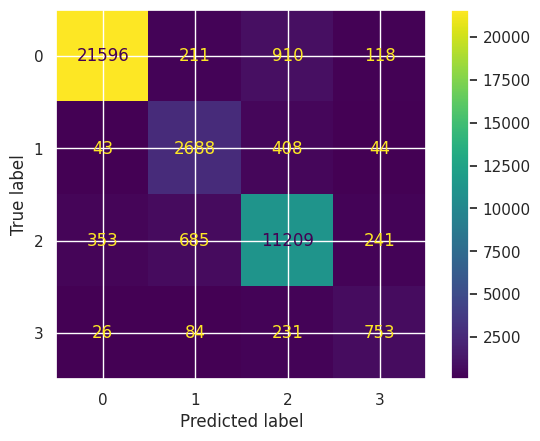

In [227]:
display = ConfusionMatrixDisplay(confusion_matrix = cfm)
display.plot()
plt.show()

## LinearSVC +  HalvingGridSearchCV

In [228]:
# preprocessing = ColumnTransformer([
#     ("text",TfidfVectorizer(max_features = 2000,ngram_range = (1,2),stop_words = "english",sublinear_tf = True,min_df = 5,max_df = 0.9,preprocessor = normalize_text),"comment"),
    
#     ("num",Pipeline([
#         ("imputer",SimpleImputer(strategy = "mean")),
#         ("scale",StandardScaler(with_mean = False))]),['emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1',
       # 'if_2', 'disability', 'year', 'month', 'day', 'total_emoticon', 'vote',
       # 'if', 'vote_emoticon', 'year_num', 'if_emoticon', 'if_vote']),
#     ("cat",OneHotEncoder(handle_unknown = "ignore"),['race', 'religion', 'gender'])

# ])
# pipeline = Pipeline([
#     ("pre",preprocessing),
#     ("model",LinearSVC(max_iter = 3000,
#                        class_weight = "balanced",
#                        random_state =42))
# ])


# param_grid = {
#     "model__C":[0.01,0.1,1,3,10],
#     "model__loss":["squared_hinge"]
# }

# hgscv = HalvingGridSearchCV(
#     estimator = pipeline,
#     param_grid = param_grid,
#     cv = 3,
#     factor = 3,
#     scoring = "f1_macro",
#     n_jobs = -1,
#     verbose = 2
# )

# hgscv.fit(xtrain,ytrain)

# model = hgscv.best_estimator_

# predict = model.predict(xtest)
# print(f1_score(ytest,predict,average = "macro")) #0.5212265365097343
# LinearSVC_hyper = model.predict(test)  #0.51663 V112



## LogisticRegression + GridSearchCV

In [229]:
# xtrain.drop(["post_id","emoticon_2","if_1","vote"],axis = 1,inplace = True)
# preprocessing = ColumnTransformer([
#     ("text",TfidfVectorizer(max_features = 50000,ngram_range = (1,2),stop_words = "english",sublinear_tf = True,min_df = 5,max_df = 0.9),"comment"),
    
#     ("num",Pipeline([
#         ("imputer",SimpleImputer(strategy = "mean")),
#         ("scale",StandardScaler())]),['emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1',
       # 'if_2', 'disability', 'year', 'month', 'day', 'total_emoticon', 'vote',
       # 'if', 'vote_emoticon', 'year_num', 'if_emoticon', 'if_vote']),
#     ("cat",OneHotEncoder(handle_unknown = "ignore"),['race','religion'])
# ])

# pipeline = Pipeline([
#     ("pre",preprocessing),
#     ("model",LogisticRegression(max_iter = 3000,class_weight = "balanced",solver = "saga",n_jobs = -1))
# ])

# param_grid = {
#     "model__C":[0.5,1,2,5]

# }
# cv = StratifiedKFold(n_splits = 5)
# gscv = GridSearchCV(
#     estimator = pipeline,
#     param_grid = param_grid,
#     cv = cv,
#     scoring = "f1_macro", # imp for inbalance data
#     n_jobs = -1,
#     verbose = 2
# )

# gscv.fit(xtrain,ytrain)

# model = gscv.best_estimator_ 
# predict = model.predict(xtest)
# print(f1_score(ytest,predict,average = "macro")) 
# LogisticRegression_hyper = model.predict(test)  #0.76976 V77

# Model comparision

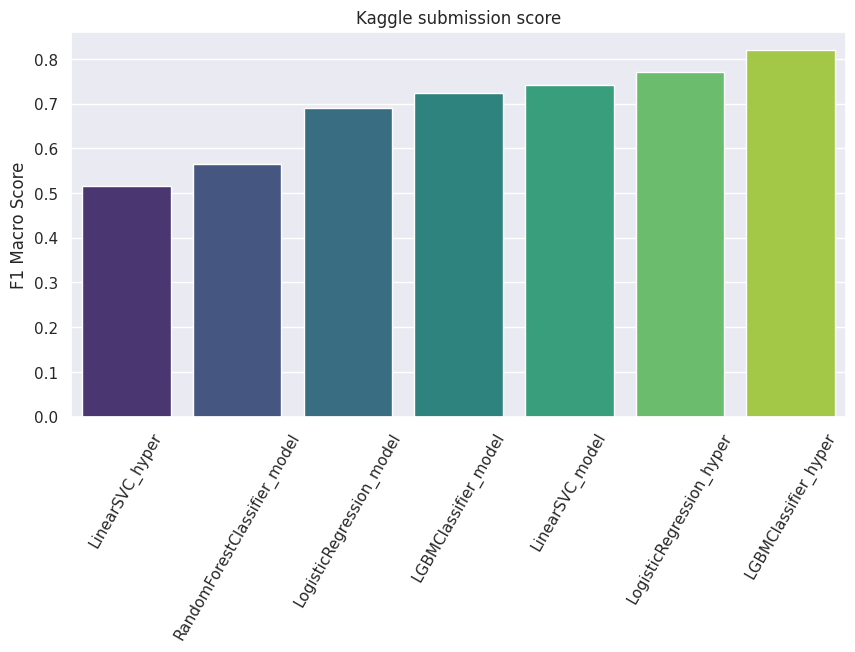

In [230]:
# model comparision
dict_={"LinearSVC_hyper" : 0.51663,"RandomForestClassifier_model":0.56417,"LogisticRegression_model" : 0.69017,
     "LGBMClassifier_model" : 0.72362,"LinearSVC_model":0.74255,"LogisticRegression_hyper" : 0.76976,
      "LGBMClassifier_hyper" : 0.82
     }
plt.figure(figsize = (10,5))
sns.barplot(x = list(dict_.keys()),y = list(dict_.values()),palette = "viridis")
plt.xticks(rotation = 60)
plt.ylabel("F1 Macro Score")
plt.title("Kaggle submission score")
plt.show();



**LGBMClassifier_hyper** model  given me a highest score among all the models

# Submission

In [231]:

submission["label"]  = predict_pipeline
submission.to_csv("/kaggle/working/submission.csv",index = False)

In [232]:
submission

,ID,label
0,1,2
1,2,2
2,3,0
3,4,0
4,5,2
...,...,...
101995,101996,0
101996,101997,0
101997,101998,0
101998,101999,0


In [233]:
submission["label"].value_counts()

label
0    56674
2    33133
1     9254
3     2939
Name: count, dtype: int64

In [234]:
print(test .shape,submission.shape)

(102000, 45) (102000, 2)
